# FitPulse – Personalized Fitness and Activity Analytics Using Big Data

**Faculty demonstration notebook.** Every number in this notebook is computed live from the
project's actual dataset by the project's actual code (`data/prepare_raw_dataset.py`,
`etl/spark_etl.py`) followed by Apache Spark / Spark MLlib. Nothing is typed in by hand —
re-running the notebook top-to-bottom reproduces every value (fixed seed = 42).

> **How to read this notebook:** each section has (1) a short explanation, (2) code,
> (3) the actual output, (4) an interpretation. All result tables are also saved to
> `faculty_evidence/`.

## 1. Project Overview

FitPulse turns daily wearable fitness data into personalized insights. The pipeline that is
**actually implemented in this repository**:

```
Kaggle FitLife dataset (687,701 rows / 3,000 participants)
        │  data/prepare_raw_dataset.py   (pandas, one-time: sample 437 users, clean, unit conversions)
        ▼
data/raw/fitpulse_raw.csv               Bronze layer – raw landing zone
        │  etl/spark_etl.py              (Apache Spark: cleaning, window/lag features, per-user goals)
        ▼
data/processed/fitpulse_silver/         Silver layer – Parquet, partitioned by month
        │  this notebook                 (Spark MLlib: supervised models E1-E5, sections 5-7)
        ▼
Personalized insights                   models/*.py, models/recommendation_engine.py
        ▼
Dashboard                               dashboard/app.py (Streamlit)
```

**What is and isn't implemented (verified by inspecting the repository):**

| Component | Status in this repo |
|---|---|
| Raw preprocessing | ✅ `data/prepare_raw_dataset.py` (pandas) |
| Apache Spark / PySpark ETL | ✅ `etl/spark_etl.py`, `etl/spark_benchmarks.py` – runs in Spark **local mode** (`local[*]`) |
| Distributed storage | ✅ Single-node Hadoop HDFS 3.4.1 (NameNode + DataNode, replication 1) holds Bronze and Silver; verified in **§11**. Sections 1-10 were executed on local Parquet (the explicit fallback) before HDFS existed. No fault tolerance (one node) |
| Random Forest, Logistic Regression, Gradient-Boosted Trees | ✅ supervised classifiers E1-E4 in **Spark MLlib** (§5-7): `models/sup_e1_*.py` ... `sup_e4_*.py`; the original scikit-learn model is `models/train_goal_achievement.py` |
| K-Means clustering | ❌ **removed**: the faculty asked for supervised learning only, so both K-Means experiments were replaced by supervised classifiers (E3, E4); the code is kept in `archive/kmeans/` |
| Linear Regression (calories) | ✅ `models/train_calorie_regression.py` kept as **E5**, with Random Forest and GBT regressors added (`models/sup_e5_calories.py`, §7.2) |
| 70/15/15 split | ✅ E1 and E5 use a seeded 70/15/15 split; E2 is **chronological**, E3 is stratified 5-fold cross-validation, E4 is **user-held-out** (§5) |
| Dashboard | ✅ **Power BI** (`powerbi/FitPulse_PowerBI_Dashboard.pbix`, built and checked in Power BI Desktop; imports CSV, not HDFS) is the primary dashboard (§12). The earlier Streamlit app (`dashboard/app.py`) is legacy/optional |

### Environment setup

Configures Java/Spark for this machine. On this Windows laptop a portable JDK 17 and the
Hadoop Windows binaries (`winutils.exe`, `hadoop.dll`) live in `../tools/` (Spark 4 needs
JDK 17/21; the system JDK 23/25 is too new for Hadoop's security APIs).

In [1]:
import os, sys, re, json, time, shutil, hashlib, subprocess, importlib.util, contextlib, io, warnings
warnings.filterwarnings("ignore", message="IProgress not found")   # harmless tqdm notice from kagglehub
from pathlib import Path

PROJECT_ROOT = Path.cwd()
assert (PROJECT_ROOT / "etl" / "spark_etl.py").exists(), "Start Jupyter from inside the FitPulse/ folder"

TOOLS = PROJECT_ROOT.parent / "tools"          # local JDK 17 + Hadoop winutils for this machine
if (TOOLS / "jdk17").exists():
    os.environ["JAVA_HOME"] = str(TOOLS / "jdk17")
if (TOOLS / "hadoop").exists():
    os.environ["HADOOP_HOME"] = str(TOOLS / "hadoop")
for var in ("HADOOP_HOME", "JAVA_HOME"):
    if var in os.environ:
        os.environ["PATH"] = str(Path(os.environ[var]) / "bin") + os.pathsep + os.environ["PATH"]
if (TOOLS / "tmp").exists():                   # keep Spark temp files off the (full) C: drive
    os.environ["TMP"] = os.environ["TEMP"] = str(TOOLS / "tmp")
os.environ.setdefault("KAGGLEHUB_CACHE", str(TOOLS / "kagglehub"))
os.environ["PYSPARK_PYTHON"] = os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
os.environ["PYTHONIOENCODING"] = "utf-8"

EVIDENCE = PROJECT_ROOT / "faculty_evidence"
EVIDENCE.mkdir(exist_ok=True)
SEED = 42                                       # one seed for every random operation in this notebook

java = shutil.which("java")
java_version = subprocess.run([java, "-version"], capture_output=True, text=True).stderr.splitlines()[0]
print("Project root :", PROJECT_ROOT)
print("Python       :", sys.version.split()[0], "-", sys.executable)
print("Java         :", java_version)
print("JAVA_HOME    :", os.environ.get("JAVA_HOME"))
print("HADOOP_HOME  :", os.environ.get("HADOOP_HOME"))

Project root : D:\bigdata\fitpulsee\FitPulse
Python       : 3.12.10 - D:\bigdata\fitpulsee\.venv\Scripts\python.exe
Java         : openjdk version "17.0.20.1" 2026-08-18
JAVA_HOME    : D:\bigdata\fitpulsee\tools\jdk17
HADOOP_HOME  : D:\bigdata\fitpulsee\tools\hadoop


In [2]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)

# Chart styling: thin marks, recessive grid, one blue for single-series charts
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "axes.edgecolor": MUTED, "axes.labelcolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.axisbelow": True,
})


def run_project_script(rel_path, log_name):
    # Runs one of the project's own pipeline scripts exactly as `python <script>` would,
    # prints its real stdout, and saves it to faculty_evidence/ as a log.
    t0 = time.time()
    proc = subprocess.run([sys.executable, rel_path], cwd=PROJECT_ROOT, capture_output=True,
                          text=True, encoding="utf-8", errors="replace")
    elapsed = time.time() - t0
    log = f"$ python {rel_path}\nexit code: {proc.returncode}   elapsed: {elapsed:.1f}s\n\n{proc.stdout}"
    (EVIDENCE / log_name).write_text(log, encoding="utf-8")
    print(log)
    if proc.returncode != 0:
        print(proc.stderr[-4000:])
        raise RuntimeError(f"{rel_path} failed")


def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

## 2. Dataset Description

### 2.1 Dataset Source

* **Original source:** Kaggle – [`jijagallery/fitlife-health-and-fitness-tracking-dataset`](https://www.kaggle.com/datasets/jijagallery/fitlife-health-and-fitness-tracking-dataset)
  (version 1). It is a *wearable-style* health & fitness tracking dataset (one row per participant-day).
  Important honesty note: it is a public, research/teaching dataset, not exported from our own devices.
* **Raw preparation:** `data/prepare_raw_dataset.py` samples **437 participants** (seed 42) and keeps each
  one's full yearly time series, then reshapes the columns into a wearable-export schema.
* **Bronze layer:** `data/raw/fitpulse_raw.csv` – the input to Spark.

Below, the project's two pipeline scripts are **actually executed** (not simulated). The SHA-256 hash
of the Bronze file before and after proves the raw preparation is exactly reproducible.

In [3]:
# Step 0 - raw preparation (project script, unchanged logic)
RAW_PATH = "data/raw/fitpulse_raw.csv"
hash_before = sha256(RAW_PATH) if Path(RAW_PATH).exists() else None
run_project_script("data/prepare_raw_dataset.py", "log_prepare_raw_dataset.txt")
hash_after = sha256(RAW_PATH)
print("SHA-256 before:", hash_before)
print("SHA-256 after :", hash_after)
print("Bronze file reproduced byte-for-byte:", hash_before == hash_after)

$ python data/prepare_raw_dataset.py
exit code: 0   elapsed: 6.9s

Source: D:\bigdata\fitpulsee\tools\kagglehub\datasets\jijagallery\fitlife-health-and-fitness-tracking-dataset\versions\1\health_fitness_dataset.csv
Wrote data/raw/fitpulse_raw.csv: 100,122 rows, 23 columns, 437 users
Date range: 2024-01-01 to 2024-12-25

SHA-256 before: 9f186fb21adb6fb38fc00781e51b11ce802a5d901eae54318e781bde94d69606
SHA-256 after : 9f186fb21adb6fb38fc00781e51b11ce802a5d901eae54318e781bde94d69606
Bronze file reproduced byte-for-byte: True


In [4]:
# Step 1 - Spark ETL, Bronze -> Silver (project script, unchanged)
SILVER_PATH = "data/processed/fitpulse_silver"
run_project_script("etl/spark_etl.py", "log_spark_etl.txt")

$ python etl/spark_etl.py
exit code: 0   elapsed: 27.5s

[1/7] Reading Bronze layer (raw CSV) into a Spark DataFrame
[2/7] Cleaning & validation
[3/7] Feature engineering — day-of-week, rest-day flag, month partition key
[4/7] Rolling averages & lag features (Spark Window functions)
[5/7] Personalized goals — per-user MapReduce aggregation
[6/7] Deriving goal_achieved / calorie_goal_achieved labels
[7/7] Writing Silver layer as partitioned Parquet (HDFS-style storage)

--- Summary ---
Bronze rows read      : 100,122
Rows after cleaning   : 100,122 (0 dropped)
Silver rows written   : 100,122
Silver columns        : 39
Users                 : 437
Written to            : data/processed/fitpulse_silver/ (partitioned by month)
SUCCESS: The process with PID 16568 (child process of PID 14676) has been terminated.
SUCCESS: The process with PID 14676 (child process of PID 22804) has been terminated.
SUCCESS: The process with PID 22804 (child process of PID 25100) has been terminated.



**Interpretation:** both pipeline stages ran successfully on this machine. The Spark ETL read the
Bronze CSV, applied its cleaning rules, engineered the features, and wrote the Silver layer as
Parquet partitioned by month. Everything below reads those real outputs.

Now we start this notebook's own Spark session (the ETL script stopped its own session when it finished).

In [5]:
from pyspark.sql import SparkSession, Window
from pyspark.sql import functions as F
from pyspark.sql import types as T

builder = (
    SparkSession.builder
    .appName("FitPulse-Faculty-Demo")
    .master("local[*]")                                   # same execution mode as etl/spark_etl.py
    .config("spark.sql.shuffle.partitions", "8")          # same setting as etl/spark_etl.py
    .config("spark.driver.memory", "2g")
    .config("spark.driver.host", "127.0.0.1")
)
if (TOOLS / "tmp").exists():
    builder = builder.config("spark.local.dir", str(TOOLS / "tmp"))
spark = builder.getOrCreate()
spark.sparkContext.setLogLevel("ERROR")
print("Spark version:", spark.version, "| master:", spark.sparkContext.master,
      "| default parallelism:", spark.sparkContext.defaultParallelism)

Spark version: 4.0.1 | master: local[*] | default parallelism: 12


In [6]:
# The original Kaggle file - located with the project's own resolve_source() function
spec = importlib.util.spec_from_file_location("prepare_raw_dataset", PROJECT_ROOT / "data" / "prepare_raw_dataset.py")
prepare_raw_dataset = importlib.util.module_from_spec(spec)
spec.loader.exec_module(prepare_raw_dataset)
SOURCE_PATH = prepare_raw_dataset.resolve_source()

source = spark.read.csv(SOURCE_PATH, header=True, inferSchema=True)
bronze = spark.read.csv(RAW_PATH, header=True, inferSchema=True)      # identical call to spark_etl.py
silver = spark.read.parquet(SILVER_PATH)

print("Kaggle source file :", SOURCE_PATH)
print("Bronze file        :", RAW_PATH)
print("Silver dataset     :", SILVER_PATH)

Kaggle source file : D:\bigdata\fitpulsee\tools\kagglehub\datasets\jijagallery\fitlife-health-and-fitness-tracking-dataset\versions\1\health_fitness_dataset.csv
Bronze file        : data/raw/fitpulse_raw.csv
Silver dataset     : data/processed/fitpulse_silver


### 2.2 Dataset Dimensions

In [7]:
def dims(df, name):
    users_col = "participant_id" if "participant_id" in df.columns else "user_id"
    agg = df.agg(F.countDistinct(users_col).alias("users"), F.min("date").alias("first"),
                 F.max("date").alias("last")).first()
    return {"Layer": name, "Rows": df.count(), "Columns": len(df.columns), "Users": agg["users"],
            "First date": str(agg["first"])[:10], "Last date": str(agg["last"])[:10]}

dataset_summary = pd.DataFrame([dims(source, "Kaggle source"), dims(bronze, "Bronze (raw CSV)"),
                                dims(silver, "Silver (Spark output)")])
dataset_summary.to_csv(EVIDENCE / "dataset_summary.csv", index=False)
display(dataset_summary)

,Layer,Rows,Columns,Users,First date,Last date
0,Kaggle source,687701,22,3000,2024-01-01,2024-12-25
1,Bronze (raw CSV),100122,23,437,2024-01-01,2024-12-25
2,Silver (Spark output),100122,39,437,2024-01-01,2024-12-25


In [8]:
# Equivalent direct calls on the Bronze DataFrame
print("bronze.count()      =", bronze.count())
print("len(bronze.columns) =", len(bronze.columns))
print("bronze.columns      =", bronze.columns)
print()
print("silver.count()      =", silver.count())
print("len(silver.columns) =", len(silver.columns))
print("Columns added by Spark ETL:", [c for c in silver.columns if c not in bronze.columns])

bronze.count()      = 100122
len(bronze.columns) = 23
bronze.columns      = ['user_id', 'date', 'steps', 'calories_burned', 'distance_km', 'active_minutes', 'sedentary_minutes', 'resting_heart_rate', 'avg_heart_rate', 'max_heart_rate', 'sleep_minutes', 'sleep_quality_score', 'activity_type', 'intensity', 'age', 'gender', 'height_cm', 'weight_kg', 'bmi', 'health_condition', 'smoking_status', 'stress_level', 'hydration_level']



silver.count()      = 100122
len(silver.columns) = 39
Columns added by Spark ETL: ['day_of_week', 'is_rest_day', 'steps_lag1', 'steps_lag2', 'steps_lag7', 'calories_lag1', 'sleep_quality_lag1', 'steps_roll7_avg', 'calories_roll7_avg', 'active_minutes_roll7_avg', 'resting_hr_roll7_avg', 'daily_step_goal', 'daily_calorie_goal', 'goal_achieved', 'calorie_goal_achieved', 'month']


**Interpretation:** the project works on a 437-user subset of the Kaggle dataset, keeping each user's
complete year of daily records so that per-user time-series features (lags, rolling averages) are
meaningful. The Spark ETL keeps every Bronze row and adds the engineered columns listed above.

### 2.3 Dataset Schema

In [9]:
print("BRONZE schema (raw CSV, types inferred by Spark):")
bronze.printSchema()

BRONZE schema (raw CSV, types inferred by Spark):
root
 |-- user_id: integer (nullable = true)
 |-- date: date (nullable = true)
 |-- steps: integer (nullable = true)
 |-- calories_burned: double (nullable = true)
 |-- distance_km: double (nullable = true)
 |-- active_minutes: integer (nullable = true)
 |-- sedentary_minutes: integer (nullable = true)
 |-- resting_heart_rate: double (nullable = true)
 |-- avg_heart_rate: integer (nullable = true)
 |-- max_heart_rate: integer (nullable = true)
 |-- sleep_minutes: integer (nullable = true)
 |-- sleep_quality_score: double (nullable = true)
 |-- activity_type: string (nullable = true)
 |-- intensity: string (nullable = true)
 |-- age: integer (nullable = true)
 |-- gender: string (nullable = true)
 |-- height_cm: double (nullable = true)
 |-- weight_kg: double (nullable = true)
 |-- bmi: double (nullable = true)
 |-- health_condition: string (nullable = true)
 |-- smoking_status: string (nullable = true)
 |-- stress_level: integer (nullab

In [10]:
print("SILVER schema (after etl/spark_etl.py):")
silver.printSchema()
_ = (EVIDENCE / "schemas.txt").write_text(
    "BRONZE\n" + bronze._jdf.schema().treeString() + "\nSILVER\n" + silver._jdf.schema().treeString(),
    encoding="utf-8")

SILVER schema (after etl/spark_etl.py):
root
 |-- user_id: integer (nullable = true)
 |-- date: date (nullable = true)
 |-- steps: integer (nullable = true)
 |-- calories_burned: double (nullable = true)
 |-- distance_km: double (nullable = true)
 |-- active_minutes: integer (nullable = true)
 |-- sedentary_minutes: integer (nullable = true)
 |-- resting_heart_rate: double (nullable = true)
 |-- avg_heart_rate: integer (nullable = true)
 |-- max_heart_rate: integer (nullable = true)
 |-- sleep_minutes: integer (nullable = true)
 |-- sleep_quality_score: double (nullable = true)
 |-- activity_type: string (nullable = true)
 |-- intensity: string (nullable = true)
 |-- age: integer (nullable = true)
 |-- gender: string (nullable = true)
 |-- height_cm: double (nullable = true)
 |-- weight_kg: double (nullable = true)
 |-- bmi: double (nullable = true)
 |-- health_condition: string (nullable = true)
 |-- smoking_status: string (nullable = true)
 |-- stress_level: integer (nullable = true)

### 2.4 Sample Records

In [11]:
print("First 10 Bronze records:")
bronze.show(10, truncate=False)

First 10 Bronze records:


+-------+----------+-----+---------------+-----------+--------------+-----------------+------------------+--------------+--------------+-------------+-------------------+---------------+---------+---+------+---------+---------+----+----------------+--------------+------------+---------------+
|user_id|date      |steps|calories_burned|distance_km|active_minutes|sedentary_minutes|resting_heart_rate|avg_heart_rate|max_heart_rate|sleep_minutes|sleep_quality_score|activity_type  |intensity|age|gender|height_cm|weight_kg|bmi |health_condition|smoking_status|stress_level|hydration_level|
+-------+----------+-----+---------------+-----------+--------------+-----------------+------------------+--------------+--------------+-------------+-------------------+---------------+---------+---+------+---------+---------+----+----------------+--------------+------------+---------------+
|1      |2024-01-01|7128 |110.1          |4.87       |41            |1003             |69.5              |103         

In [12]:
print("First 10 Silver records (one user, ordered by date) - engineered columns shown:")
(silver.filter(F.col("user_id") == silver.agg(F.min("user_id")).first()[0])
       .orderBy("date")
       .select("user_id", "date", "day_of_week", "month", "steps", "steps_lag1", "steps_lag7",
               "steps_roll7_avg", "daily_step_goal", "goal_achieved")
       .show(10, truncate=False))

First 10 Silver records (one user, ordered by date) - engineered columns shown:


+-------+----------+-----------+-------+-----+----------+----------+-----------------+---------------+-------------+
|user_id|date      |day_of_week|month  |steps|steps_lag1|steps_lag7|steps_roll7_avg  |daily_step_goal|goal_achieved|
+-------+----------+-----------+-------+-----+----------+----------+-----------------+---------------+-------------+
|1      |2024-01-01|Monday     |2024-01|7128 |NULL      |NULL      |7128.0           |9700.0         |0            |
|1      |2024-01-04|Thursday   |2024-01|7925 |7128      |NULL      |7526.5           |9700.0         |0            |
|1      |2024-01-05|Friday     |2024-01|7557 |7925      |NULL      |7536.666666666667|9700.0         |0            |
|1      |2024-01-07|Sunday     |2024-01|11120|7557      |NULL      |8432.5           |9700.0         |1            |
|1      |2024-01-09|Tuesday    |2024-01|5406 |11120     |NULL      |7827.2           |9700.0         |0            |
|1      |2024-01-10|Wednesday  |2024-01|10202|5406      |NULL   

**Interpretation:** each row is one user-day. Activity (`steps`, `active_minutes`, `calories_burned`),
heart-rate, sleep and profile columns are present. In the Silver rows the lag/rolling columns are null
for a user's earliest days because there is no earlier history yet. That is expected, and §3.1 quantifies it.

## 3. Data Quality Analysis

### 3.1 Missing Values

In [13]:
def missing_table(df):
    total = df.count()
    row = df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in df.columns]).first().asDict()
    out = pd.DataFrame({"Column": list(row), "Missing": list(row.values())})
    out["Missing %"] = (out["Missing"] / total * 100).round(2)
    return out

src_missing = missing_table(source)
bronze_missing = missing_table(bronze)
silver_missing = missing_table(silver)
src_missing.to_csv(EVIDENCE / "missing_values_source.csv", index=False)
bronze_missing.to_csv(EVIDENCE / "missing_values_bronze.csv", index=False)
silver_missing.to_csv(EVIDENCE / "missing_values_silver.csv", index=False)

print("Kaggle source - columns with missing values:")
display(src_missing[src_missing.Missing > 0])
print("Kaggle source - health_condition values (literal text, not nulls):")
source.groupBy("health_condition").count().orderBy("count", ascending=False).show()
print(f"Bronze - total missing cells: {bronze_missing.Missing.sum():,}")
display(bronze_missing.T)

Kaggle source - columns with missing values:


,Column,Missing,Missing %


Kaggle source - health_condition values (literal text, not nulls):


+----------------+------+
|health_condition| count|
+----------------+------+
|            None|490275|
|    Hypertension| 99437|
|        Diabetes| 64754|
|          Asthma| 33235|
+----------------+------+

Bronze - total missing cells: 0


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22
Column,user_id,date,steps,calories_burned,distance_km,active_minutes,sedentary_minutes,resting_heart_rate,avg_heart_rate,max_heart_rate,sleep_minutes,sleep_quality_score,activity_type,intensity,age,gender,height_cm,weight_kg,bmi,health_condition,smoking_status,stress_level,hydration_level
Missing,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Missing %,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [14]:
print("Silver - columns with missing values:")
display(silver_missing[silver_missing.Missing > 0])
n_users = silver.select("user_id").distinct().count()
print(f"Users = {n_users}.  Expected nulls: lag1 = 1 x users = {n_users}, lag2 = 2 x users = {2*n_users}, "
      f"lag7 = 7 x users = {7*n_users}")

Silver - columns with missing values:


,Column,Missing,Missing %
25,steps_lag1,437,0.44
26,steps_lag2,874,0.87
27,steps_lag7,3059,3.06
28,calories_lag1,437,0.44
29,sleep_quality_lag1,437,0.44


Users = 437.  Expected nulls: lag1 = 1 x users = 437, lag2 = 2 x users = 874, lag7 = 7 x users = 3059


**Interpretation:**
* The **Kaggle source** has no true nulls (Spark count = 0). Note that `health_condition` holds the literal
  text `"None"` for participants without a condition (cell below). pandas parses that text as NaN by
  default, which is why `prepare_raw_dataset.py` restores it with `fillna("None")`.
* The **Bronze** file has no missing values.
* In **Silver**, the only nulls are in the lag columns and they exactly equal *k × number of users*
  (the first *k* days of each user have no *k*-days-ago value). These are structural nulls, not data errors.
  They are not imputed. Rows with incomplete lag features are excluded from model training (§5).

### 3.2 Duplicate Records

In [15]:
def duplicate_report(df, key, name):
    total = df.count()
    return {"Layer": name, "Rows": total,
            "Exact duplicate rows": total - df.dropDuplicates().count(),
            "Duplicate (user, date) keys": total - df.dropDuplicates(key).count()}

dup = pd.DataFrame([
    duplicate_report(source, ["participant_id", "date"], "Kaggle source"),
    duplicate_report(bronze, ["user_id", "date"], "Bronze"),
    duplicate_report(silver, ["user_id", "date"], "Silver"),
])
dup.to_csv(EVIDENCE / "duplicate_analysis.csv", index=False)
display(dup)

,Layer,Rows,Exact duplicate rows,"Duplicate (user, date) keys"
0,Kaggle source,687701,0,0
1,Bronze,100122,0,0
2,Silver,100122,0,0


**Interpretation:** there are no exact duplicate rows and no repeated (user, date) pairs at any layer,
so every row is a unique user-day. Duplicate removal is still part of the pipeline
(`drop_duplicates()` in the raw preparation, `dropDuplicates()` in Spark). It is a safeguard that
would matter for a real device export, where re-syncs can duplicate days.

### 3.3 Statistical Summary

In [16]:
KEY_NUMERIC = ["steps", "active_minutes", "sedentary_minutes", "calories_burned",
               "avg_heart_rate", "resting_heart_rate", "sleep_minutes", "sleep_quality_score"]
bronze.select(KEY_NUMERIC).describe().show()

+-------+------------------+------------------+-----------------+-----------------+------------------+------------------+------------------+-------------------+
|summary|             steps|    active_minutes|sedentary_minutes|  calories_burned|    avg_heart_rate|resting_heart_rate|     sleep_minutes|sleep_quality_score|
+-------+------------------+------------------+-----------------+-----------------+------------------+------------------+------------------+-------------------+
|  count|            100122|            100122|           100122|           100122|            100122|            100122|            100122|             100122|
|   mean| 8624.767813267814| 69.92943608797268|947.2411158386768|662.2012954195875| 130.8155550228721| 69.96443638760165|422.82944807335053|  67.09927788098479|
| stddev|2057.2030107790038|29.094747196687283|65.36928559034504|437.7527099564095|17.766286697141744| 5.265246221872581| 58.38174969824597| 12.332894997367742|
|    min|               578|      

In [17]:
numeric_cols = [f.name for f in bronze.schema.fields
                if isinstance(f.dataType, (T.IntegerType, T.DoubleType, T.LongType)) and f.name != "user_id"]
stats = bronze.select(numeric_cols).describe().toPandas().set_index("summary").T.astype(float).round(2)
stats.to_csv(EVIDENCE / "statistical_summary.csv")
display(stats)

summary,count,mean,stddev,min,max
steps,100122.0,8624.77,2057.20,578.0,16407.00
calories_burned,100122.0,662.20,437.75,48.0,3726.70
distance_km,100122.0,6.54,1.66,0.5,15.97
active_minutes,100122.0,69.93,29.09,20.0,120.00
sedentary_minutes,100122.0,947.24,65.37,720.0,1180.00
resting_heart_rate,100122.0,69.96,5.27,56.8,85.60
avg_heart_rate,100122.0,130.82,17.77,83.0,206.00
max_heart_rate,100122.0,144.92,21.28,88.0,206.00
sleep_minutes,100122.0,422.83,58.38,240.0,600.00
sleep_quality_score,100122.0,67.10,12.33,15.8,100.00


**Interpretation:** values fall inside physiologically plausible ranges (the ranges are enforced by the
cleaning filters in §4.1). Steps average about 8,600/day. Every row has a logged activity session of at least
20 minutes. This matters later: `is_rest_day` (< 15 active minutes) is always 0 in this dataset.

## 4. Data Preprocessing

### 4.1 Data Cleaning

Cleaning happens in **two places** in the existing code. Only operations that exist in the code are listed.

| # | Operation | Why it is necessary | Where in the code |
|---|---|---|---|
| 1 | Sample 437 participants (seed 42), keeping each one's full time series | Manageable scale while preserving complete per-user histories for lag/rolling features | `data/prepare_raw_dataset.py` L84–86 |
| 2 | Exact-duplicate removal (`drop_duplicates`) | A re-synced device export can repeat days, which would double-count activity | `prepare_raw_dataset.py` L89 |
| 3 | Drop rows missing `participant_id`, `date`, `activity_type`, `duration_minutes` | These fields are required to place a record in a user's timeline | `prepare_raw_dataset.py` L90 |
| 4 | Physiological range filters (age 15–100, height 120–220 cm, weight 30–200 kg, session 0–300 min, avg HR 40–220, resting HR 35–120, sleep 0–14 h, steps 0–60,000) | Removes sensor glitches / impossible values | `prepare_raw_dataset.py` L91–96 |
| 5 | `health_condition` NaN → `"None"` | The source stores the text "None" (= no condition). pandas reads it as NaN, so it is restored | `prepare_raw_dataset.py` L97 |
| 6 | Recompute `calories_burned` with the MET formula (MET × kg × hours) | Source column was ~30× too low to be plausible | `prepare_raw_dataset.py` L99–101 |
| 7 | Unit conversions / derived raw columns: `distance_km`, `active_minutes`, `sleep_minutes`, `sedentary_minutes`, `max_heart_rate`, `sleep_quality_score` | Map the source schema onto a wearable-export schema | `prepare_raw_dataset.py` L103–126 |
| 8 | Spark `dropDuplicates()` | Same safeguard, enforced again inside the big-data pipeline | `etl/spark_etl.py` L55 |
| 9 | Spark `dropna` on `user_id`, `date`, `activity_type`, `steps` | Required fields | `spark_etl.py` L56 |
| 10 | Spark range filters (age, resting HR, avg HR, steps, sleep 0–840 min) | Re-validate physiology inside Spark | `spark_etl.py` L57–63 |
| 11 | Spark `coalesce(health_condition, "None")` | Same null rule | `spark_etl.py` L64 |
| 12 | Type conversion: `date` → Spark `DateType` (`to_date`) | Enables date arithmetic, ordering and window functions | `spark_etl.py` L65 |

**Honesty notes:** `max_heart_rate` and `sleep_quality_score` are *modelled* in step 7: they come from
formulas with seeded random noise, not from raw sensor readings. No outlier capping, imputation or
normalisation of the Silver data happens in the existing ETL. Scaling is done only inside the ML
pipelines below.

The cell below re-evaluates each cleaning rule and counts how many rows it actually removes.

In [18]:
# (a) Raw-preparation rules, re-evaluated on the Kaggle rows of the 437 sampled participants.
#     The filter expressions are copied verbatim from data/prepare_raw_dataset.py.
src = pd.read_csv(SOURCE_PATH)
sampled_ids = pd.Series(src.participant_id.unique()).sample(n=prepare_raw_dataset.N_PARTICIPANTS,
                                                            random_state=prepare_raw_dataset.SEED)
d = src[src.participant_id.isin(sampled_ids)].copy()
steps_log = [("Kaggle rows for the 437 sampled participants", len(d))]
d = d.drop_duplicates();                                   steps_log.append(("after drop_duplicates()", len(d)))
d = d.dropna(subset=["participant_id", "date", "activity_type", "duration_minutes"])
steps_log.append(("after dropna(required fields)", len(d)))
d = d[d.age.between(15, 100) & d.height_cm.between(120, 220) & d.weight_kg.between(30, 200)
      & d.duration_minutes.between(0, 300) & d.avg_heart_rate.between(40, 220)
      & d.resting_heart_rate.between(35, 120) & d.hours_sleep.between(0, 14)
      & d.daily_steps.between(0, 60000)]
steps_log.append(("after physiological range filters", len(d)))
print("health_condition values read as NaN by pandas (text 'None') and restored by fillna:", int(d.health_condition.isna().sum()))

# (b) Spark ETL rules, re-evaluated with Spark on the Bronze DataFrame (same expressions as spark_etl.py)
b = bronze
spark_log = [("Bronze rows read by Spark", b.count())]
b = b.dropDuplicates();                                    spark_log.append(("after dropDuplicates()", b.count()))
b = b.dropna(subset=["user_id", "date", "activity_type", "steps"]); spark_log.append(("after dropna(required)", b.count()))
b = b.filter(F.col("age").between(15, 100) & F.col("resting_heart_rate").between(35, 120)
             & F.col("avg_heart_rate").between(40, 220) & F.col("steps").between(0, 60000)
             & F.col("sleep_minutes").between(0, 840))
spark_log.append(("after range filters", b.count()))

clean = pd.DataFrame([("prepare_raw_dataset.py (pandas)",) + s for s in steps_log]
                     + [("spark_etl.py (Spark)",) + s for s in spark_log], columns=["Stage", "Step", "Rows"])
clean["Removed by step"] = clean.groupby("Stage")["Rows"].diff().fillna(0).astype(int).abs()
clean.to_csv(EVIDENCE / "preprocessing_summary.csv", index=False)
display(clean)
print("Bronze 'date' type:", dict(bronze.dtypes)["date"], " ->  Silver 'date' type:", dict(silver.dtypes)["date"])

health_condition values read as NaN by pandas (text 'None') and restored by fillna: 69821


,Stage,Step,Rows,Removed by step
0,prepare_raw_dataset.py (pandas),Kaggle rows for the 437 sampled participants,100122,0
1,prepare_raw_dataset.py (pandas),after drop_duplicates(),100122,0
2,prepare_raw_dataset.py (pandas),after dropna(required fields),100122,0
3,prepare_raw_dataset.py (pandas),after physiological range filters,100122,0
4,spark_etl.py (Spark),Bronze rows read by Spark,100122,0
5,spark_etl.py (Spark),after dropDuplicates(),100122,0
6,spark_etl.py (Spark),after dropna(required),100122,0
7,spark_etl.py (Spark),after range filters,100122,0


Bronze 'date' type: date  ->  Silver 'date' type: date


**Interpretation:** the table shows how many rows each rule actually removed on this dataset. The raw
preparation already does the cleaning, so the Spark ETL's identical checks remove nothing. They serve as a
second validation gate inside the big-data pipeline. The type conversion makes `date` a real date type,
which the window functions in §4.2 depend on.

### 4.2 Feature Engineering

Features engineered in **`etl/spark_etl.py`** (Spark), plus the few added for modelling:

| Feature | Definition | Why | Where |
|---|---|---|---|
| `day_of_week` | Monday…Sunday from `date` | Weekly activity rhythm | `spark_etl.py` L69 |
| `month` | `yyyy-MM`; also the Parquet partition key | Seasonality + partition pruning | `spark_etl.py` L70 |
| `is_rest_day` | 1 if `active_minutes` < 15 | Rest-day indicator. **Always 0 in this dataset** (shown below) | `spark_etl.py` L72 |
| `steps_lag1/2/7`, `calories_lag1`, `sleep_quality_lag1` | Value 1/2/7 days earlier for the same user (`lag()` over a user window) | Recent personal history | `spark_etl.py` L79–86 |
| `steps_roll7_avg`, `calories_roll7_avg`, `active_minutes_roll7_avg`, `resting_hr_roll7_avg` | Trailing 7-row average per user | Smoothed personal trend | `spark_etl.py` L80, L88–91 |
| `daily_step_goal`, `daily_calorie_goal` | 1.10 × user's own average, rounded (to 100 steps / 10 kcal), via `groupBy(user_id).agg()` + broadcast join | **Personalized** goals (MapReduce pattern) | `spark_etl.py` L99–115 |
| `goal_achieved`, `calorie_goal_achieved` | 1 if the day's value ≥ the personal goal | Daily goal labels | `spark_etl.py` L118–121 |
| `month_sin`, `month_cos` | Cyclical month encoding | Seasonality without one-hot | used by E2 (§6.2) |
| `steps_roll7_avg` and the other `*_roll7_avg` columns | Trailing 7-row average **including the current row** | Silver-level convenience columns. **Not used** as features of same-day or next-day goal models: their window contains the prediction day (shown as the INVALID leakage run in §6.2). E2 builds its own windows that end at -1 | see §6.2 |

The cell below checks the Spark features by recomputing them by hand for one user.

In [19]:
DEMO_USER = 1503      # the user behind dashboard login `demo1` (etl/setup_auth.py)
u = (silver.filter(F.col("user_id") == DEMO_USER).orderBy("date")
           .select("date", "day_of_week", "month", "steps", "steps_lag1", "steps_lag2", "steps_lag7",
                   "steps_roll7_avg", "active_minutes", "is_rest_day", "daily_step_goal", "goal_achieved")
           .toPandas())
display(u.head(9))

# Manual re-computation for the 8th record of this user
i = 7
manual_roll = u.steps.iloc[i-6:i+1].mean()
print(f"Row {i+1}: steps_roll7_avg (Spark) = {u.steps_roll7_avg.iloc[i]:.2f}   manual mean of last 7 steps = {manual_roll:.2f}")
print(f"Row {i+1}: steps_lag7 (Spark)      = {u.steps_lag7.iloc[i]:.0f}   manual steps 7 rows earlier = {u.steps.iloc[i-7]}")
user_avg = u.steps.mean()
print(f"Personal goal: round(1.10 x {user_avg:.2f}, -2) = {round(user_avg * 1.10, -2):.0f}   Spark daily_step_goal = {u.daily_step_goal.iloc[0]:.0f}")
assert np.isclose(manual_roll, u.steps_roll7_avg.iloc[i]) and u.steps_lag7.iloc[i] == u.steps.iloc[i-7]

,date,day_of_week,month,steps,steps_lag1,steps_lag2,steps_lag7,steps_roll7_avg,active_minutes,is_rest_day,daily_step_goal,goal_achieved
0,2024-01-01,Monday,2024-01,7235,NaN,NaN,NaN,7235.000000,77,0,9400.0,0
1,2024-01-02,Tuesday,2024-01,7421,7235.0,NaN,NaN,7328.000000,79,0,9400.0,0
2,2024-01-03,Wednesday,2024-01,8102,7421.0,7235.0,NaN,7586.000000,66,0,9400.0,0
3,2024-01-04,Thursday,2024-01,5712,8102.0,7421.0,NaN,7117.500000,63,0,9400.0,0
4,2024-01-05,Friday,2024-01,6659,5712.0,8102.0,NaN,7025.800000,75,0,9400.0,0
5,2024-01-06,Saturday,2024-01,9430,6659.0,5712.0,NaN,7426.500000,109,0,9400.0,1
6,2024-01-09,Tuesday,2024-01,8681,9430.0,6659.0,NaN,7605.714286,117,0,9400.0,0
7,2024-01-10,Wednesday,2024-01,6618,8681.0,9430.0,7235.0,7517.571429,41,0,9400.0,0
8,2024-01-11,Thursday,2024-01,8481,6618.0,8681.0,7421.0,7669.000000,120,0,9400.0,0


Row 8: steps_roll7_avg (Spark) = 7517.57   manual mean of last 7 steps = 7517.57
Row 8: steps_lag7 (Spark)      = 7235   manual steps 7 rows earlier = 7235
Personal goal: round(1.10 x 8579.92, -2) = 9400   Spark daily_step_goal = 9400


In [20]:
print("is_rest_day value counts in Silver:")
silver.groupBy("is_rest_day").count().show()
print("Minimum active_minutes in the dataset:", silver.agg(F.min("active_minutes")).first()[0])
goal_rate = silver.agg(F.avg("goal_achieved")).first()[0]
print(f"Share of user-days where the personalized step goal was achieved: {goal_rate:.2%}")

is_rest_day value counts in Silver:


+-----------+------+
|is_rest_day| count|
+-----------+------+
|          0|100122|
+-----------+------+



Minimum active_minutes in the dataset: 20


Share of user-days where the personalized step goal was achieved: 33.75%


**Interpretation:** the Spark lag/rolling/goal features match the manual calculation exactly.
`is_rest_day` exists in the code but is constant (0) here, because every row in this dataset has a logged
session of at least 20 minutes. It is therefore **not** used as a model feature. Note that "7-day" lag
and rolling features are computed over the user's previous 7 *records*, and users have gaps between
records, as `spark_etl.py` implements it.

### 4.3 Final Feature Set

In [4]:
# Feature sets of the SUPERVISED experiments E1-E5 (read from the experiment scripts themselves, so they cannot drift apart)
import sys, importlib
sys.path.insert(0, str(PROJECT_ROOT / "models"))
e1m = importlib.import_module("spark_report_classification")
e2m = importlib.import_module("sup_e2_goal_next_day")
e3m = importlib.import_module("sup_e3_user_high_achiever")
e4m = importlib.import_module("sup_e4_activity_level")
e5m = importlib.import_module("train_calorie_regression")

feature_set = pd.DataFrame(
    [("E1 same-day goal", f, "numeric") for f in e1m.NUM] + [("E1 same-day goal", f, "categorical") for f in e1m.CAT] + [("E1 same-day goal", "label (steps >= 8000)", "TARGET")]
    + [("E2 next-day goal", f, "numeric (history before day t / calendar / profile)") for f in e2m.NUM] + [("E2 next-day goal", f, "categorical") for f in e2m.CAT] + [("E2 next-day goal", "label (steps(t) >= 8000)", "TARGET")]
    + [("E3 high_achiever", f, "numeric (per-user average)") for f in e3m.FEATURES] + [("E3 high_achiever", "high_achiever (goal rate > median user)", "TARGET")]
    + [("E4 activity level", f, "numeric") for f in e4m.NUM] + [("E4 activity level", f, "categorical") for f in e4m.CAT] + [("E4 activity level", "label (active_minutes > median)", "TARGET")]
    + [("E5 calories", f, "numeric") for f in e5m.NUM] + [("E5 calories", f, "categorical") for f in e5m.CAT] + [("E5 calories", e5m.TARGET, "TARGET")],
    columns=["Experiment", "Column", "Role"])
(EVIDENCE / "supervised").mkdir(exist_ok=True)
feature_set.to_csv(EVIDENCE / "supervised" / "final_feature_set_E1_E5.csv", index=False)
display(feature_set.groupby("Experiment").Role.value_counts().unstack(fill_value=0))
display(feature_set)

Role,TARGET,categorical,numeric,numeric (history before day t / calendar / profile),numeric (per-user average)
Experiment,,,,,
E1 same-day goal,1,3,15,0,0
E2 next-day goal,1,2,0,18,0
E3 high_achiever,1,0,0,0,9
E4 activity level,1,3,13,0,0
E5 calories,1,1,9,0,0


,Experiment,Column,Role
0,E1 same-day goal,active_minutes,numeric
1,E1 same-day goal,sedentary_minutes,numeric
2,E1 same-day goal,calories_burned,numeric
3,E1 same-day goal,avg_heart_rate,numeric
4,E1 same-day goal,max_heart_rate,numeric
...,...,...,...
73,E5 calories,height_cm,numeric
74,E5 calories,weight_kg,numeric
75,E5 calories,bmi,numeric
76,E5 calories,gender,categorical


## 5. Supervised learning protocol (all five experiments are supervised)

The faculty asked for **supervised** learning. The two K-Means experiments were therefore replaced (their code is in `archive/`),
and every experiment now predicts a *labelled target* from features:

| Id | Task | Label | Unit / rows | Evaluation (headline) | Models |
|---|---|---|---|---|---|
| **E1** | same-day goal classification | `GoalAchieved = 1 if steps >= 8000` | user-day, 100,122 | random 70/15/15 split, seed 42 (unchanged) | Random Forest (unchanged), Logistic Regression, Gradient-Boosted Trees |
| **E2** | next-day goal prediction (rebuilt) | `steps(t) >= 8000`, features from days before *t* only | user-day with history | **chronological** split by date | Random Forest, Gradient-Boosted Trees, Logistic Regression |
| **E3** | user-level classifier (replaces K-Means on 437 users) | `high_achiever = 1` if the user's goal rate is above the median user | user, 437 | stratified 5-fold cross-validation (every user tested once) | Random Forest, Logistic Regression |
| **E4** | user-day activity level (replaces K-Means on user-days) | `High` if `active_minutes` is above the median | user-day | **user-held-out** 70/15/15 (no user in two sets) | Random Forest, Gradient-Boosted Trees, Logistic Regression |
| **E5** | same-day calorie regression (kept) | `calories_burned` (kcal) | user-day | seeded hash split of (user, date) 70/15/15 + chronological check | Linear Regression (unchanged), Random Forest Regressor, GBT Regressor |

**Rules applied to every experiment**
1. **Seed 42** for every random operation (splits, trees, scikit-learn cross-checks).
2. **Tune on the validation set only.** The test set is scored once per final model.
3. **Leakage rules.** `steps`, `distance_km`, `user_id`, `date`, `smoking_status`, `health_condition` are never features of a goal model, and nothing derived from
   steps of the prediction day is either. Every experiment also runs once *with* a leaky feature; that score is stored with status **INVALID** and is never a result.
4. **Baseline comparison** (always predicting the majority class, or the training mean for regression) next to every score.
5. **Unseen-data evaluation**: unseen users, later dates, or cross-validation folds, never a plain random split alone for a headline number that could leak across neighbouring days.
6. **Independent scikit-learn cross-check** of the metrics (section 7.3).

**Data note: several columns are partly derived in this demonstration dataset** (`data/prepare_raw_dataset.py`).
`calories_burned = MET(activity_type, intensity) x weight_kg x duration / 60`; `active_minutes` is that session duration;
`sedentary_minutes = 1440 - sleep_minutes - active_minutes`; `distance_km = steps x stride(height, intensity)`;
`max_heart_rate` = average heart rate + an intensity margin + noise (capped at 220 - age); `sleep_quality_score` is a formula of sleep hours, stress and resting heart rate plus noise.
So *calories, distance, minutes, max heart rate and sleep quality are partly derived*: a model that scores well on them may only be recovering a formula, and several
leakage demonstrations below exist precisely because of that.

100,122 user-days, 437 users, 2024-01-01 to 2024-12-25
within-user correlation of weight_kg with calendar month = 0.992; median within-user weight range = 58.8 kg
   -> weight_kg behaves like a calendar clock in this synthetic data (a real person does not gain ~60 kg in a year).
sedentary_minutes == max(0, 1440 - sleep_minutes - active_minutes) for 100.0% of rows


month,1,2,3,4,5,6,7,8,9,10,11,12
mean_steps,8892.578,9607.202,10121.632,10054.083,9635.105,8988.097,7998.789,7290.170,6851.603,6795.574,7301.090,7931.948
goal_rate,0.696,0.830,0.890,0.885,0.824,0.717,0.498,0.328,0.239,0.224,0.326,0.489
user_days,9025.000,9126.000,10246.000,9962.000,9810.000,8768.000,8197.000,7440.000,6781.000,7090.000,7175.000,6502.000


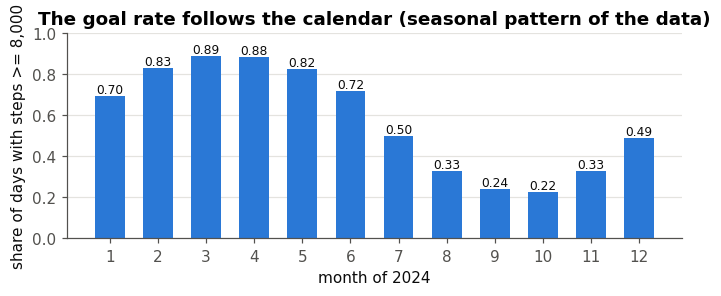

In [5]:
# Dataset facts that explain several results below (computed here from the Silver Parquet, not typed)
silver_pd = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "fitpulse_silver")
silver_pd["date"] = pd.to_datetime(silver_pd["date"])
silver_pd = silver_pd.drop_duplicates(["user_id", "date"])
silver_pd["month"] = silver_pd["date"].dt.month
print(f"{len(silver_pd):,} user-days, {silver_pd.user_id.nunique()} users, {silver_pd.date.min().date()} to {silver_pd.date.max().date()}")

w = silver_pd.weight_kg - silver_pd.groupby("user_id").weight_kg.transform("mean")
m = silver_pd.month - silver_pd.groupby("user_id").month.transform("mean")
rng = silver_pd.groupby("user_id").weight_kg.agg(lambda x: x.max() - x.min())
print(f"within-user correlation of weight_kg with calendar month = {np.corrcoef(w, m)[0, 1]:.3f}; median within-user weight range = {rng.median():.1f} kg")
print("   -> weight_kg behaves like a calendar clock in this synthetic data (a real person does not gain ~60 kg in a year).")
print("sedentary_minutes == max(0, 1440 - sleep_minutes - active_minutes) for",
      f"{(silver_pd.sedentary_minutes == (1440 - silver_pd.sleep_minutes - silver_pd.active_minutes).clip(lower=0)).mean():.1%} of rows")

by_month = silver_pd.groupby("month").agg(mean_steps=("steps", "mean"), goal_rate=("steps", lambda x: (x >= 8000).mean()), user_days=("steps", "size"))
display(by_month.round(3).T)
fig, ax = plt.subplots(figsize=(6.4, 2.8))
bars = ax.bar(by_month.index, by_month.goal_rate, color=BLUE, width=0.62)
for b, v in zip(bars, by_month.goal_rate):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.2f}", ha="center", va="bottom", fontsize=8, color=INK)
ax.set_xticks(range(1, 13)); ax.set_ylim(0, 1); ax.set_xlabel("month of 2024"); ax.set_ylabel("share of days with steps >= 8,000")
ax.set_title("The goal rate follows the calendar (seasonal pattern of the data)"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

In [6]:
# Helpers for sections 5-7. Every table and chart is READ from the files written by models/sup_e1_*.py ... sup_e5_*.py
# (exports/E<n>_results.csv, exports/E<n>_feature_importance.csv, faculty_evidence/supervised/).
import sys
from matplotlib.patches import Patch
sys.path.insert(0, str(PROJECT_ROOT / "models"))
EXPORTS = PROJECT_ROOT / "exports"
SUP = EVIDENCE / "supervised"
ACC, F1W, F1M, AUC = "Accuracy", "F1 (weighted)", "F1 (macro)", "ROC AUC"
P1, R1, F11 = "Precision (positive class)", "Recall (positive class)", "F1 (positive class)"
BASE = "Baseline accuracy (always majority class)"
MAE, RMSE, R2 = "MAE (kcal)", "RMSE (kcal)", "R2"

def results(exp):
    return pd.read_csv(EXPORTS / f"{exp}_results.csv")

def wide(res, split, metrics, status=("VALID",)):
    d = res[(res.split_type == split) & res.status.isin(status)]
    return d.pivot_table(index="model", columns="metric", values="value", aggfunc="first").reindex(columns=metrics)

def invalid_rows(res, metrics):
    d = res[res.status == "INVALID"].pivot_table(index="model", columns="metric", values="value", aggfunc="first")
    return d[[c for c in metrics if c in d.columns]]

def info(exp):
    return json.loads((SUP / f"{exp}_run_info.json").read_text(encoding="utf-8"))

def model_bars(tab, metric, baseline=None, title="", fmt="{:.3f}", ylim=None, baseline_label="majority-class baseline"):
    fig, ax = plt.subplots(figsize=(6.4, 3.0))
    bars = ax.bar(tab.index, tab[metric], color=BLUE, width=0.5)
    for b, v in zip(bars, tab[metric]):
        ax.text(b.get_x() + b.get_width() / 2, v, fmt.format(v), ha="center", va="bottom", color=INK, fontsize=9)
    if baseline is not None:
        ax.axhline(baseline, color=MUTED, ls="--", lw=1.2, label=f"{baseline_label} {fmt.format(baseline)}")
        ax.legend(loc="upper right", frameon=False, fontsize=8)
    ax.set_title(title); ax.set_ylabel(metric); ax.grid(axis="x", visible=False)
    if ylim: ax.set_ylim(*ylim)
    long = max(len(str(n)) for n in tab.index) > 18
    plt.xticks(fontsize=8, rotation=20 if long else 0, ha="right" if long else "center"); plt.tight_layout(); plt.show()

def validity_chart(res, valid_split, metric, title):
    v = res[(res.split_type == valid_split) & (res.status == "VALID") & (res.metric == metric)][["model", "value"]].assign(kind="valid")
    i = res[(res.status == "INVALID") & (res.metric == metric)][["model", "value"]].assign(kind="INVALID (leakage)")
    d = pd.concat([v, i]).reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(7.4, 0.36 * len(d) + 1.2))
    bars = ax.barh(range(len(d)), d.value, color=[BLUE if k == "valid" else ORANGE for k in d.kind], height=0.62)
    for b, k in zip(bars, d.kind):
        if k != "valid":
            b.set_hatch("///"); b.set_edgecolor("white")
    ax.set_yticks(range(len(d))); ax.set_yticklabels([n.replace(" (LEAKAGE)", "") for n in d.model], fontsize=7.5)
    ax.invert_yaxis(); ax.grid(axis="y", visible=False)
    for y, val in enumerate(d.value):
        ax.text(val, y, f" {val:.3f}", va="center", fontsize=8, color=INK)
    ax.legend(handles=[Patch(color=BLUE, label="valid"), Patch(facecolor=ORANGE, hatch="///", edgecolor="white", label="INVALID (leakage)")],
              loc="lower right", frameon=False, fontsize=8)
    ax.set_xlabel(metric); ax.set_title(title); plt.tight_layout(); plt.show()

def importance_chart(exp, model, n=10):
    imp = pd.read_csv(EXPORTS / f"{exp}_feature_importance.csv")
    d = imp[imp.model == model].nlargest(n, "importance").iloc[::-1]
    fig, ax = plt.subplots(figsize=(6.4, 0.3 * len(d) + 1.1))
    ax.barh(d.feature, d.importance, color=BLUE, height=0.6)
    for y, val in enumerate(d.importance):
        ax.text(val, y, f" {val:.3f}", va="center", fontsize=8, color=INK)
    ax.set_title(f"{exp} {model}: top {len(d)} feature importances (impurity)"); ax.grid(axis="y", visible=False)
    plt.tight_layout(); plt.show()

def gains(tab, metric, base, label="baseline"):
    for name in tab.index:
        print(f"  {name:26s} {metric} {tab.loc[name, metric]:.4f} = {label} {base:.4f} {100 * (tab.loc[name, metric] - base):+.1f} points")

print("helpers ready; results are read from", EXPORTS, "and", SUP)

helpers ready; results are read from D:\bigdata\fitpulsee\FitPulse\exports and D:\bigdata\fitpulsee\FitPulse\faculty_evidence\supervised


## 6. Goal prediction: E1, E2 and E3

### 6.1 E1 - same-day goal classification

**Question:** given a day's *other* measurements, was the 8,000-step goal reached that day? **Label:** `GoalAchieved = 1 if steps >= 8000`.
**E1 is unchanged:** the same Random Forest (18 features: 15 numeric including the engineered `active_ratio`, and 3 categorical), seed 42, the same
70/15/15 `randomSplit` and the same selected setting (`models/spark_report_classification.py`, imported not edited). Added on exactly the same rows and features:
**Logistic Regression** (one-hot + standardised, `regParam` tuned on validation) and **Gradient-Boosted Trees** (depth x iterations tuned on validation ROC-AUC).
**Never features:** `steps`, `distance_km`, `user_id`, `date`, `smoking_status`, `health_condition`.

E1 features (18): numeric ['active_minutes', 'sedentary_minutes', 'calories_burned', 'avg_heart_rate', 'max_heart_rate', 'resting_heart_rate', 'sleep_minutes', 'sleep_quality_score', 'active_ratio', 'age', 'bmi', 'height_cm', 'weight_kg', 'stress_level', 'hydration_level'] + categorical ['intensity', 'activity_type', 'gender']
records 100,122; split {'Training': 70383, 'Validation': 14943, 'Test': 14796}; same split as the existing E1 run: True
settings: Random Forest {'numTrees': 50, 'maxDepth': 15} | Logistic Regression {'reg': 0.0} | GBT {'depth': 5, 'iters': 100}
the unchanged Random Forest is reproduced: max |difference| to the existing E1 metrics = 1.6e-06

E1 comparison table - TEST set (random 70/15/15, seed 42):


metric,Accuracy,F1 (weighted),ROC AUC,Baseline accuracy (always majority class)
model,,,,
Gradient-Boosted Trees,0.7382,0.7381,0.7735,0.6144
Logistic Regression,0.7356,0.7305,0.7396,0.6144
Random Forest,0.7352,0.7346,0.7585,0.6144


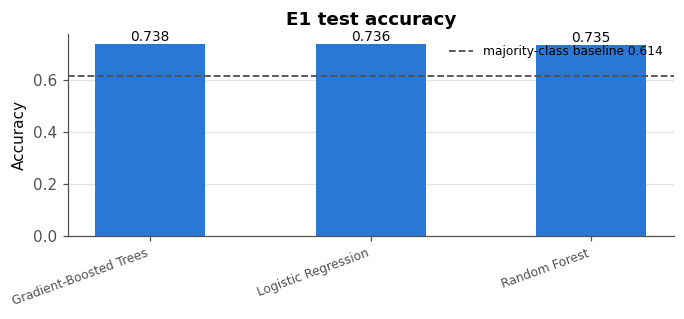

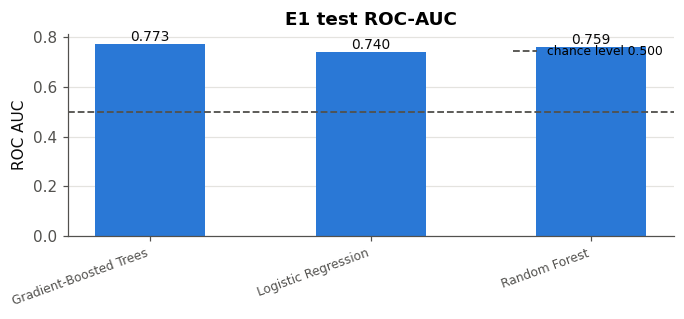

VALIDATION set (used for tuning):


metric,Accuracy,F1 (weighted),ROC AUC,Baseline accuracy (always majority class)
model,,,,
Gradient-Boosted Trees,0.7293,0.7289,0.7701,0.6096
Logistic Regression,0.7333,0.7283,0.7365,0.6096
Random Forest,0.7293,0.7282,0.7549,0.6096


USER-HELD-OUT check (15% of users never seen in training):


metric,Accuracy,F1 (weighted),ROC AUC,Baseline accuracy (always majority class)
model,,,,
Gradient-Boosted Trees,0.7224,0.7223,0.7608,0.6168
Logistic Regression,0.7315,0.7275,0.7340,0.6168
Random Forest,0.7232,0.7232,0.7498,0.6168


LEAKAGE test - the same models with steps and distance_km added (status INVALID, never a result):


metric,Accuracy,F1 (weighted),ROC AUC,status
model,,,,
Gradient-Boosted Trees + steps & distance_km (LEAKAGE),0.9903,0.9903,0.9996,INVALID
Logistic Regression + steps & distance_km (LEAKAGE),0.9999,0.9999,1.0000,INVALID
Random Forest + steps & distance_km (LEAKAGE),0.9895,0.9895,0.9996,INVALID


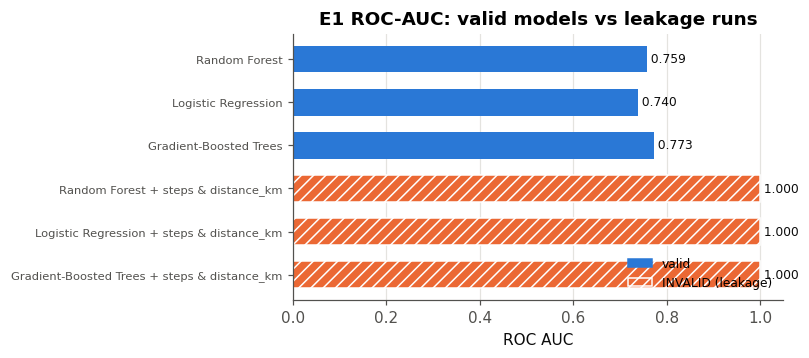

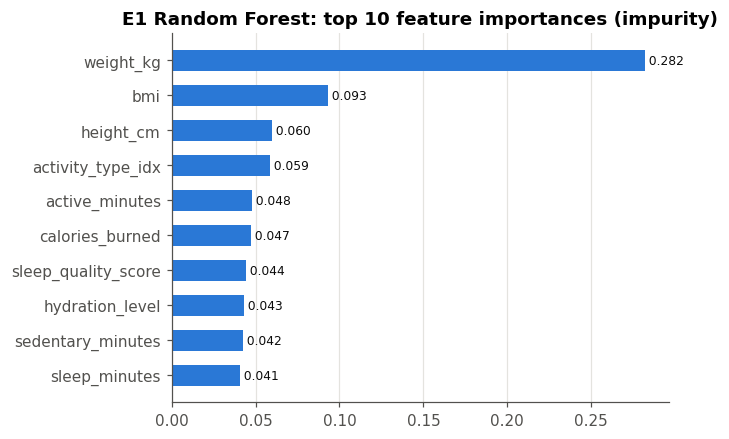

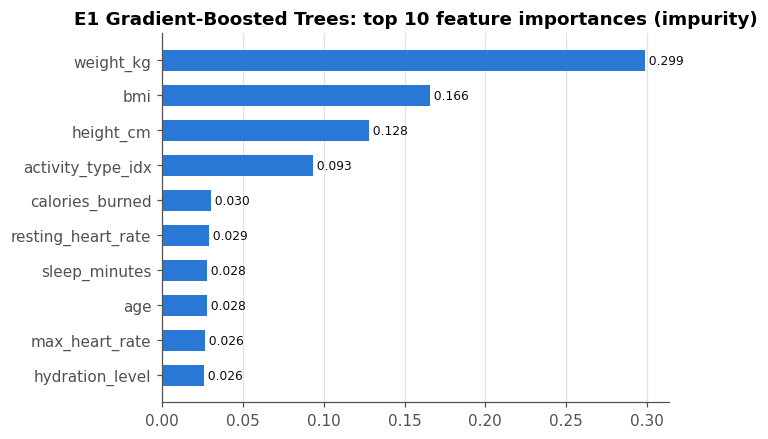


Interpretation (computed from the tables above)
  Gradient-Boosted Trees     Accuracy 0.7382 = majority baseline 0.6144 +12.4 points
  Logistic Regression        Accuracy 0.7356 = majority baseline 0.6144 +12.1 points
  Random Forest              Accuracy 0.7352 = majority baseline 0.6144 +12.1 points
  user-held-out accuracy: {'Gradient-Boosted Trees': 0.7224, 'Logistic Regression': 0.7315, 'Random Forest': 0.7232} against baseline 0.6168
  with steps/distance_km the score becomes accuracy 0.990-1.000: the label is a threshold on steps, so the run is INVALID.


In [7]:
import spark_report_classification as e1_old          # the unchanged E1 Random Forest code
r1, i1 = results("E1"), info("E1")
print(f"E1 features ({len(e1_old.NUM) + len(e1_old.CAT)}): numeric {e1_old.NUM} + categorical {e1_old.CAT}")
print(f"records {i1['records']:,}; split {i1['split_sizes']}; same split as the existing E1 run: {i1['same_split_as_existing_E1']}")
print(f"settings: Random Forest {i1['rf_setting']} | Logistic Regression {i1['logreg_setting']} | GBT {i1['gbt_setting']}")
print(f"the unchanged Random Forest is reproduced: max |difference| to the existing E1 metrics = {i1['reproduction_max_abs_diff']:.1e}\n")

cols = [ACC, F1W, AUC, BASE]
t1 = wide(r1, "test", cols)
print("E1 comparison table - TEST set (random 70/15/15, seed 42):")
display(t1.round(4))
base1 = t1[BASE].iloc[0]
model_bars(t1, ACC, base1, "E1 test accuracy")
model_bars(t1, AUC, 0.5, "E1 test ROC-AUC", baseline_label="chance level")
print("VALIDATION set (used for tuning):"); display(wide(r1, "validation", cols).round(4))
print("USER-HELD-OUT check (15% of users never seen in training):"); display(wide(r1, "test (user-held-out)", cols).round(4))
print("LEAKAGE test - the same models with steps and distance_km added (status INVALID, never a result):")
display(invalid_rows(r1, [ACC, F1W, AUC]).round(4).assign(status="INVALID"))
validity_chart(r1, "test", AUC, "E1 ROC-AUC: valid models vs leakage runs")
importance_chart("E1", "Random Forest"); importance_chart("E1", "Gradient-Boosted Trees")

print("\nInterpretation (computed from the tables above)")
gains(t1, ACC, base1, "majority baseline")
uh = wide(r1, "test (user-held-out)", cols)
print("  user-held-out accuracy:", {m: round(float(uh.loc[m, ACC]), 4) for m in uh.index}, "against baseline", round(float(uh[BASE].iloc[0]), 4))
lk = invalid_rows(r1, [ACC, AUC])
print(f"  with steps/distance_km the score becomes accuracy {lk[ACC].min():.3f}-{lk[ACC].max():.3f}: the label is a threshold on steps, so the run is INVALID.")

**Reading E1.** All three models beat the 61.4% majority baseline by a similar margin, and the margin survives when whole users are held out, so the models are not memorising individual users.
The most important feature of both tree models is `weight_kg`. Section 5 showed that, inside each user, `weight_kg` follows the calendar almost linearly in this synthetic data,
so it can act as a **clock** for the seasonal pattern in the goal rate. E1 is deliberately unchanged, so this is stated as a limitation rather than removed (no ablation was run for E1).
The leakage run (`steps`, `distance_km` added) is near-perfect and is **INVALID**: it measures a threshold, not learning.

### 6.2 E2 - next-day goal prediction (rebuilt)

**Question:** using only what was recorded *before* day *t*, will the user reach 8,000 steps on day *t*? **Label:** `steps(t) >= 8000`.
The previous version reused Silver's rolling columns, whose window **includes** the current row (`steps_roll7_avg` uses `rowsBetween(-6, 0)`), and headlined a random split.
Rebuilt:
* every history feature is a Spark window function `Window.partitionBy("user_id").orderBy("date")` with the frame **ending at -1** (`rowsBetween(-7, -1)`, `rowsBetween(-3, -1)`) or a `lag()`, so day *t* never sees itself or later days;
* only rows whose previous logged row is exactly the previous calendar day, with at least 3 earlier rows, are used;
* features = history windows + calendar of day *t* (day of week, month sin/cos) + static profile (age, gender, BMI, height, **baseline weight** = BMI x height squared; raw `weight_kg` is replaced because it works as a calendar clock);
* **chronological split**: earliest 70% of the date span for training, the next 15% for validation, the latest 15% for the test block. The random split is shown only as a labelled contrast;
* Random Forest, Gradient-Boosted Trees and Logistic Regression, tuned on the validation block only.

usable rows 64,174; split cut dates ['2024-09-08', '2024-11-02']; settings {'rf': {'depth': 5}, 'gbt': {'depth': 3, 'iters': 50}, 'logreg': {'reg': 0.0}}


,split,rows,positive_share,cut_train_end,cut_validation_end
0,train,50014,0.7378,2024-09-08,2024-11-02
1,validation,6513,0.2246,2024-09-08,2024-11-02
2,test,7647,0.4114,2024-09-08,2024-11-02


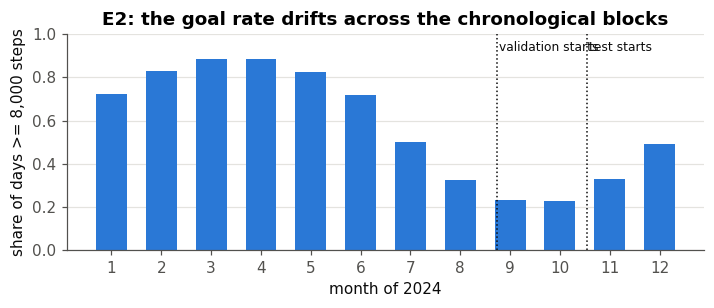

E2 comparison table - CHRONOLOGICAL TEST block (headline):


metric,Accuracy,Precision (positive class),Recall (positive class),F1 (positive class),ROC AUC,Baseline accuracy (always majority class),Baseline accuracy (always TRAINING-majority class)
model,,,,,,,
Gradient-Boosted Trees,0.5991,0.5080,0.8039,0.6226,0.6970,0.5886,0.4114
Logistic Regression,0.6835,0.6649,0.4654,0.5475,0.7004,0.5886,0.4114
Random Forest,0.5823,0.4954,0.8179,0.6170,0.6706,0.5886,0.4114


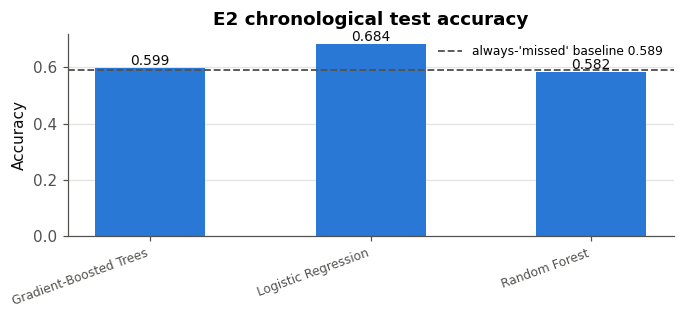

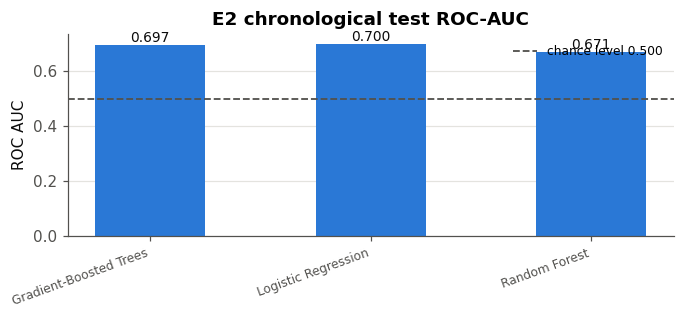

VALIDATION block:


metric,Accuracy,Precision (positive class),Recall (positive class),F1 (positive class),ROC AUC,Baseline accuracy (always majority class)
model,,,,,,
Gradient-Boosted Trees,0.7546,0.4251,0.2618,0.3240,0.6470,0.7754
Logistic Regression,0.7344,0.4195,0.4757,0.4459,0.6529,0.7754
Random Forest,0.7453,0.4120,0.3137,0.3562,0.6502,0.7754


LEAKAGE test - Silver's steps_roll7_avg (window includes the prediction day) added (INVALID):


metric,Accuracy,F1 (positive class),ROC AUC,status
model,,,,
Gradient-Boosted Trees + rolling mean INCLUDING the prediction day (LEAKAGE),0.7551,0.7064,0.8257,INVALID
Logistic Regression + rolling mean INCLUDING the prediction day (LEAKAGE),0.7984,0.7515,0.8787,INVALID
Random Forest + rolling mean INCLUDING the prediction day (LEAKAGE),0.6175,0.6369,0.7518,INVALID


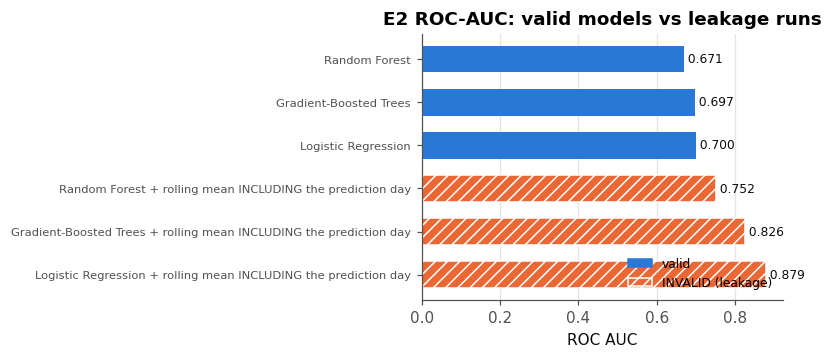

CONTRAST ONLY - a RANDOM split of the same rows (not the headline; neighbouring days leak across it):


metric,Accuracy,F1 (positive class),ROC AUC,Baseline accuracy (always majority class)
model,,,,
Gradient-Boosted Trees,0.7780,0.8348,0.8301,0.6459
Logistic Regression,0.7770,0.8348,0.8295,0.6459
Random Forest,0.7732,0.8296,0.8191,0.6459


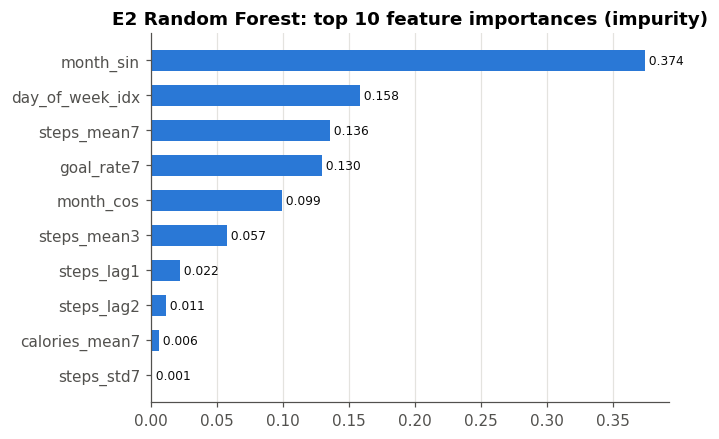

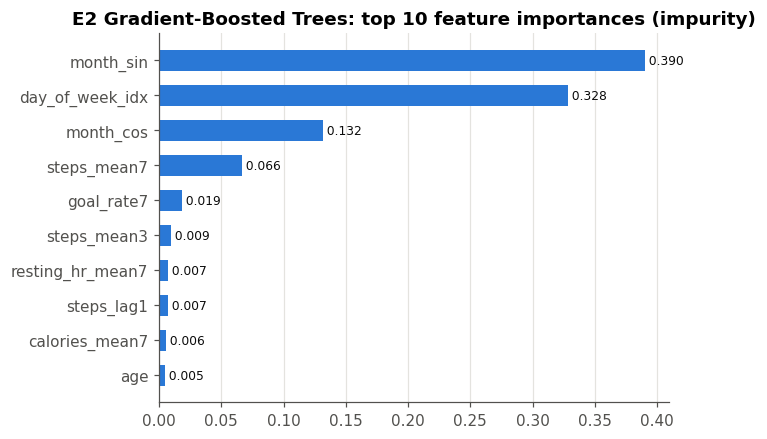


Interpretation (computed from the tables above)
  share of days meeting the goal: train 0.738, validation 0.225, test 0.411
  test-majority baseline (always 'missed') 0.5886; training-majority baseline (always 'achieved') 0.4114
  Gradient-Boosted Trees     Accuracy 0.5991 = always-'missed' baseline 0.5886 +1.0 points
  Logistic Regression        Accuracy 0.6835 = always-'missed' baseline 0.5886 +9.5 points
  Random Forest              Accuracy 0.5823 = always-'missed' baseline 0.5886 -0.6 points
  the random split gives accuracy 0.773-0.778, the chronological block 0.582-0.684: the random split is optimistic.


In [8]:
r2, i2 = results("E2"), info("E2")
sp2 = pd.read_csv(SUP / "E2_split_summary.csv")
print(f"usable rows {i2['usable_rows']:,}; split cut dates {i2['split_cuts']}; settings {i2['settings']}")
display(sp2.round(4))
f2 = pd.read_csv(SUP / "predictions" / "E2_features.csv", usecols=["date", "split", "label"], parse_dates=["date"])
mm = f2.assign(month=f2.date.dt.month).groupby("month").label.mean()
fig, ax = plt.subplots(figsize=(6.6, 2.9))
ax.bar(mm.index, mm.values, color=BLUE, width=0.62)
frac = lambda d: pd.Timestamp(d).month - 0.5 + (pd.Timestamp(d).day - 1) / pd.Timestamp(d).days_in_month   # month m is centred on x = m
c1, c2 = (frac(x) for x in i2["split_cuts"])
for x, lab in ((c1, "validation starts"), (c2, "test starts")):
    ax.axvline(x, color=INK, ls=":", lw=1); ax.text(x + 0.05, 0.97, lab, fontsize=8, va="top", color=INK)
ax.set_xticks(range(1, 13)); ax.set_ylim(0, 1); ax.set_xlabel("month of 2024"); ax.set_ylabel("share of days >= 8,000 steps")
ax.set_title("E2: the goal rate drifts across the chronological blocks"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

BASE_TR = "Baseline accuracy (always TRAINING-majority class)"
cols2 = [ACC, P1, R1, F11, AUC, BASE]
t2 = wide(r2, "chronological test", cols2)
t2[BASE_TR] = r2[(r2.split_type == "chronological test") & (r2.metric == BASE_TR)].value.iloc[0]
print("E2 comparison table - CHRONOLOGICAL TEST block (headline):"); display(t2.round(4))
model_bars(t2, ACC, t2[BASE].iloc[0], "E2 chronological test accuracy", baseline_label="always-'missed' baseline")
model_bars(t2, AUC, 0.5, "E2 chronological test ROC-AUC", baseline_label="chance level")
print("VALIDATION block:"); display(wide(r2, "validation", cols2).round(4))
print("LEAKAGE test - Silver's steps_roll7_avg (window includes the prediction day) added (INVALID):")
display(invalid_rows(r2, [ACC, F11, AUC]).round(4).assign(status="INVALID"))
validity_chart(r2, "chronological test", AUC, "E2 ROC-AUC: valid models vs leakage runs")
print("CONTRAST ONLY - a RANDOM split of the same rows (not the headline; neighbouring days leak across it):")
display(wide(r2, "random split (NOT headline)", [ACC, F11, AUC, BASE], status=("REFERENCE",)).round(4))
importance_chart("E2", "Random Forest"); importance_chart("E2", "Gradient-Boosted Trees")

print("\nInterpretation (computed from the tables above)")
pos = sp2.set_index("split").positive_share
print(f"  share of days meeting the goal: train {pos['train']:.3f}, validation {pos['validation']:.3f}, test {pos['test']:.3f}")
print(f"  test-majority baseline (always 'missed') {t2[BASE].iloc[0]:.4f}; training-majority baseline (always 'achieved') {t2[BASE_TR].iloc[0]:.4f}")
gains(t2, ACC, t2[BASE].iloc[0], "always-'missed' baseline")
rnd = wide(r2, "random split (NOT headline)", [ACC, AUC], status=("REFERENCE",))
print(f"  the random split gives accuracy {rnd[ACC].min():.3f}-{rnd[ACC].max():.3f}, the chronological block {t2[ACC].min():.3f}-{t2[ACC].max():.3f}: the random split is optimistic.")

**Reading E2.** The honest next-day signal is weak. The goal rate falls from the first months to the last, so the training days are mostly 'achieved' while the test block is mostly 'missed':
a model trained on the early months over-predicts 'achieved' later (high recall, low precision for the tree models). Compare accuracy with the **always-'missed' baseline of the test block**, not with
the random-split figure. ROC-AUC (about 0.67-0.70) is the fairer summary of ranking ability under this shift. The leakage run, which adds the rolling mean that includes the prediction day, scores higher and is **INVALID**.

### 6.3 E3 - user-level classifier `high_achiever` (replaces K-Means on 437 users)

One row per **user** (437 rows). **Label:** `high_achiever = 1` if the user's goal-achievement rate over *all* their days (share of days with steps >= 8,000) is **above the median** across users.
**Features (9, none step- or distance-based):** age, BMI, height, baseline weight (BMI x height squared, see section 5), average heart rate, average sleep minutes, average active minutes, average stress, average hydration.
**Evaluation:** stratified 5-fold cross-validation (every user is in a test fold exactly once). Inside each training part the hyper-parameters are chosen on an inner validation part (nested), so no test user influences tuning.
Metrics are pooled over the out-of-fold predictions; fold mean and standard deviation are also stored. Models: Random Forest and Logistic Regression against the majority-class baseline.
Two *reference* runs (not claims of skill): the logging window alone, and the raw average `weight_kg`.

users 437; high achievers 218; median goal rate 0.6136; features ['age', 'bmi', 'height_cm', 'weight_baseline_kg', 'avg_heart_rate', 'avg_sleep_minutes', 'avg_active_minutes', 'avg_stress', 'avg_hydration']
settings chosen inside each fold: {'Random Forest': [{'trees': 100, 'depth': 4}, {'trees': 100, 'depth': 2}, {'trees': 100, 'depth': 2}, {'trees': 100, 'depth': 2}, {'trees': 100, 'depth': 2}], 'Logistic Regression': [{'reg': 10.0}, {'reg': 10.0}, {'reg': 0.01}, {'reg': 10.0}, {'reg': 10.0}]}
users and high achievers per fold:


fold,0,1,2,3,4
users,88.0,88.0,88.0,87.0,86.0
high_achievers,44.0,44.0,44.0,43.0,43.0


leakage rule check: no step- or distance-based average among the features -> OK

E3 comparison table (pooled out-of-fold predictions):


metric,Accuracy,F1 (weighted),ROC AUC,Baseline accuracy (always majority class)
model,,,,
Logistic Regression,0.5378,0.5361,0.5486,0.5011
Random Forest,0.5355,0.5318,0.5425,0.5011


metric,Accuracy (mean over folds),Accuracy (sd over folds),ROC AUC (mean over folds),ROC AUC (sd over folds)
model,,,,
Logistic Regression,0.5379,0.0442,0.5725,0.0332
Random Forest,0.5354,0.0406,0.5446,0.0377


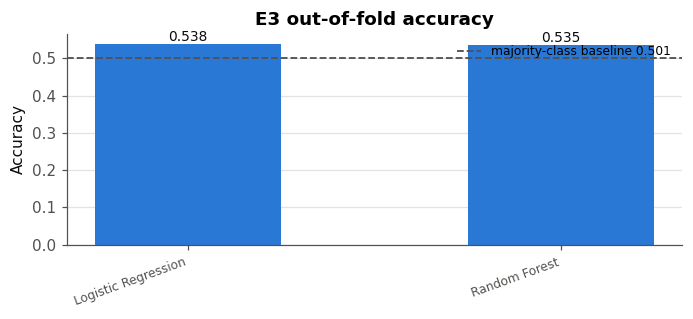

LEAKAGE test - the user's average steps added (INVALID):


metric,Accuracy,ROC AUC,Baseline accuracy (always majority class),status
model,,,,
Logistic Regression + average steps (LEAKAGE),0.7368,0.8242,0.5011,INVALID
Random Forest + average steps (LEAKAGE),0.7323,0.7978,0.5011,INVALID


REFERENCE runs (not valid claims of skill):


metric,Accuracy,ROC AUC
model,,
Logistic Regression: logging-window coverage ONLY (mean logged month),0.5835,0.6195
Logistic Regression: raw average weight_kg instead of baseline weight (ablation),0.5469,0.5721
Random Forest: logging-window coverage ONLY (mean logged month),0.5675,0.6077
Random Forest: raw average weight_kg instead of baseline weight (ablation),0.5423,0.5408


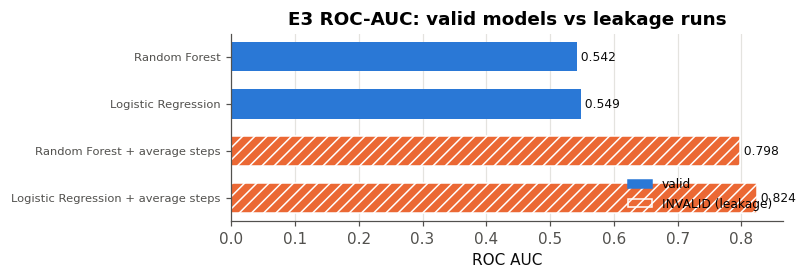

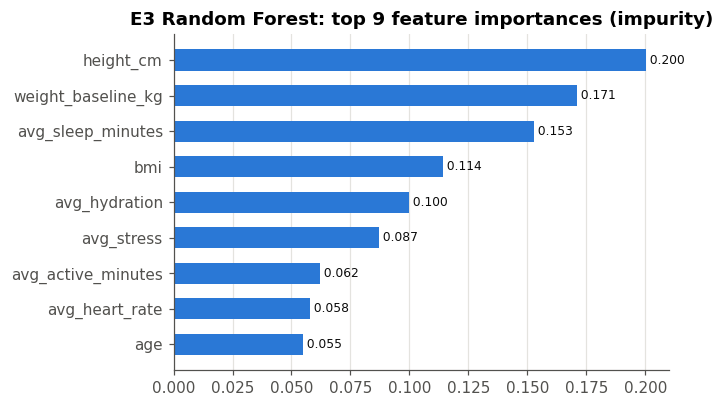


Interpretation (computed from the tables above)
  Logistic Regression  235/437 users classified correctly; majority baseline 0.5011; one-sided binomial p = 0.069 (p > 0.05 means not distinguishable from the baseline)
  Random Forest        234/437 users classified correctly; majority baseline 0.5011; one-sided binomial p = 0.083 (p > 0.05 means not distinguishable from the baseline)


In [9]:
r3, i3 = results("E3"), info("E3")
SPLIT3 = "stratified 5-fold CV (out-of-fold)"
print(f"users {i3['users']}; high achievers {i3['high_achievers']}; median goal rate {i3['median_rate']:.4f}; features {i3['features']}")
print("settings chosen inside each fold:", i3["chosen_settings_per_fold"])
ut = pd.read_csv(SUP / "predictions" / "E3_user_table.csv")
print("users and high achievers per fold:"); display(ut.groupby("fold").label.agg(users="count", high_achievers="sum").T)
assert not any(("step" in f) or ("distance" in f) for f in i3["features"]), "a step/distance-based feature is present"
print("leakage rule check: no step- or distance-based average among the features -> OK")

cols3 = [ACC, F1W, AUC, BASE]
t3 = wide(r3, SPLIT3, cols3)
print("\nE3 comparison table (pooled out-of-fold predictions):"); display(t3.round(4))
display(wide(r3, SPLIT3, ["Accuracy (mean over folds)", "Accuracy (sd over folds)", "ROC AUC (mean over folds)", "ROC AUC (sd over folds)"]).round(4))
model_bars(t3, ACC, t3[BASE].iloc[0], "E3 out-of-fold accuracy")
print("LEAKAGE test - the user's average steps added (INVALID):"); display(invalid_rows(r3, [ACC, AUC, BASE]).round(4).assign(status="INVALID"))
print("REFERENCE runs (not valid claims of skill):")
display(r3[(r3.status == "REFERENCE") & r3.metric.isin([ACC, AUC])].pivot_table(index="model", columns="metric", values="value").round(4))
validity_chart(r3, SPLIT3, AUC, "E3 ROC-AUC: valid models vs leakage runs")
importance_chart("E3", "Random Forest", n=9)

from scipy.stats import binomtest
n_users = int(i3["users"])
print("\nInterpretation (computed from the tables above)")
for m in t3.index:
    k = round(t3.loc[m, ACC] * n_users)
    p = binomtest(k, n_users, float(t3[BASE].iloc[0]), alternative="greater").pvalue
    print(f"  {m:20s} {k}/{n_users} users classified correctly; majority baseline {t3[BASE].iloc[0]:.4f}; one-sided binomial p = {p:.3f} (p > 0.05 means not distinguishable from the baseline)")

**Reading E3.** Whether a user is a high achiever is **not predictable from their average profile** in this data: accuracy and ROC-AUC are close to the baseline and to chance, and the difference is not statistically significant.
The reference run that uses only *which months a user logged* scores higher than the real features, which shows that most of the little signal is the logging window (the goal rate is seasonal, section 5), not the person.
Adding the user's average steps raises the score, but that is the label's own ingredient, so it is **INVALID**. A negative result reported with its baseline is a valid supervised result.

## 7. Activity level and calories: E4 and E5

### 7.1 E4 - user-day activity level (replaces K-Means on user-days)

**Label:** `activity_level = High` if the day's `active_minutes` is **above the median** (the median is taken from the *training users only*), otherwise `Low`.
**Split:** user-held-out 70/15/15 by a hash of `user_id` (no user appears in two sets).
**Excluded because they encode the label:** `active_minutes` (the label), `sedentary_minutes` (= 1440 - sleep - active), `active_ratio`, `active_minutes_roll7_avg` (window includes the day), and `calories_burned`
(calories = MET x weight x duration and the duration *is* `active_minutes`, so calories + weight + activity type + intensity reconstruct the label).
**Features:** heart rates (average, maximum, resting), sleep minutes and quality, stress, hydration, steps, distance, age, BMI, height, baseline weight, and intensity, activity type, gender.
Metrics: accuracy, macro F1, ROC-AUC, confusion matrix and the majority baseline. Models: Random Forest, Gradient-Boosted Trees, Logistic Regression (tuned on the validation users only).

median active_minutes of the training users = 70.0; rows {'train': 71460, 'validation': 16404, 'test': 12258}; users {'train': 312, 'validation': 72, 'test': 53}; High share {'train': 0.4927651833193395, 'validation': 0.49536698366252135, 'test': 0.4920868004568445}
users present in BOTH train and test (must be 0): 0

E4 comparison table - TEST users never seen in training:


metric,Accuracy,F1 (macro),ROC AUC,Baseline accuracy (always majority class)
model,,,,
Gradient-Boosted Trees,0.5036,0.5002,0.4999,0.5079
Logistic Regression,0.5040,0.4442,0.4999,0.5079
Random Forest,0.5056,0.4406,0.4965,0.5079


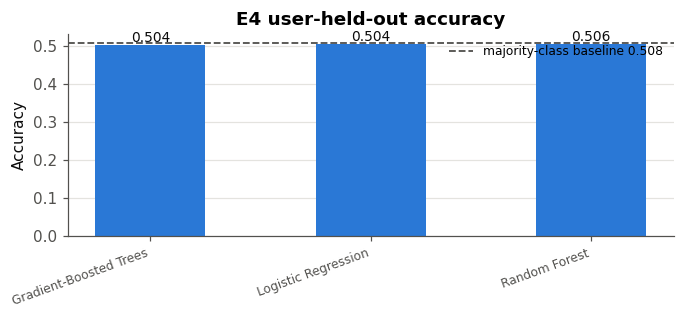

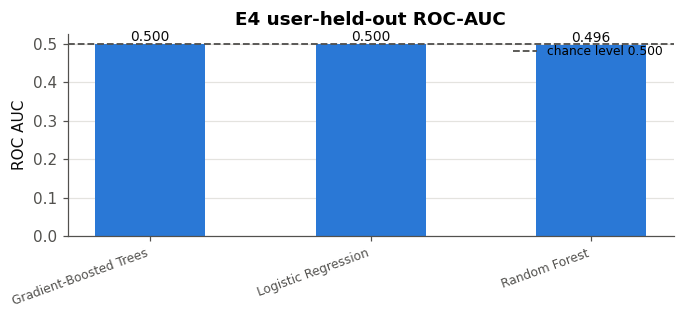

VALIDATION users:


metric,Accuracy,F1 (macro),ROC AUC,Baseline accuracy (always majority class)
model,,,,
Gradient-Boosted Trees,0.4991,0.4965,0.4969,0.5046
Logistic Regression,0.5009,0.4366,0.4968,0.5046
Random Forest,0.5032,0.4231,0.4974,0.5046


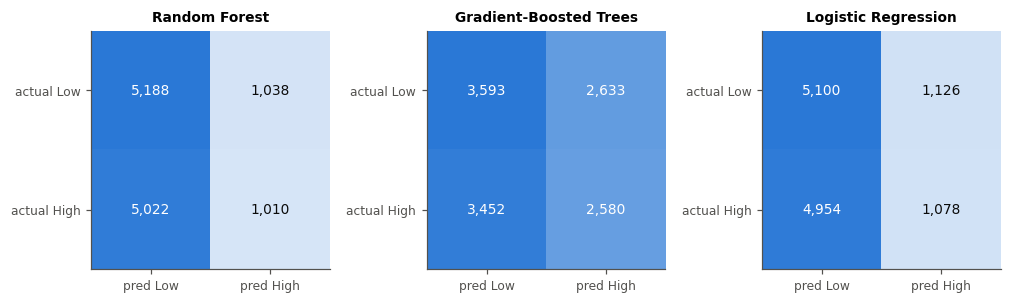

,TN (Low->Low),FP (Low->High),FN (High->Low),TP (High->High)
model,,,,
Random Forest,5188,1038,5022,1010
Gradient-Boosted Trees,3593,2633,3452,2580
Logistic Regression,5100,1126,4954,1078


LEAKAGE tests - calories_burned or sedentary_minutes added (INVALID, they encode the label):


metric,Accuracy,F1 (macro),ROC AUC,status
model,,,,
Gradient-Boosted Trees + calories_burned (LEAKAGE),0.8982,0.8982,0.9673,INVALID
Gradient-Boosted Trees + sedentary_minutes (LEAKAGE),0.9741,0.9741,0.9976,INVALID
Logistic Regression + calories_burned (LEAKAGE),0.8763,0.8763,0.9512,INVALID
Logistic Regression + sedentary_minutes (LEAKAGE),0.9693,0.9693,0.9966,INVALID
Random Forest + calories_burned (LEAKAGE),0.7878,0.7876,0.8905,INVALID
Random Forest + sedentary_minutes (LEAKAGE),0.8032,0.8030,0.9027,INVALID


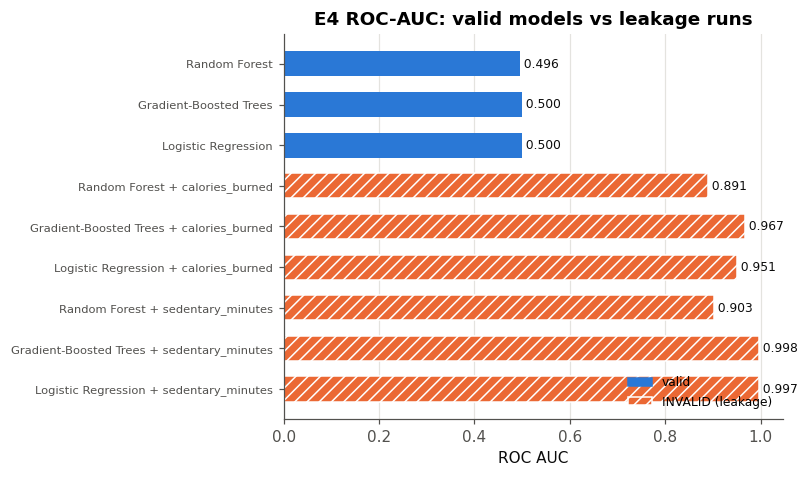

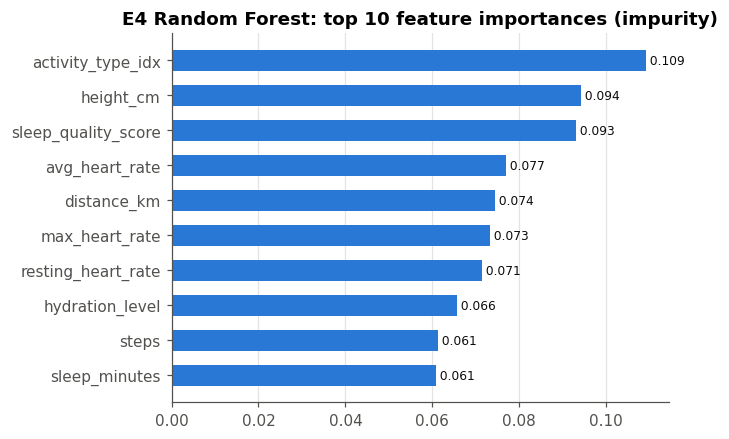

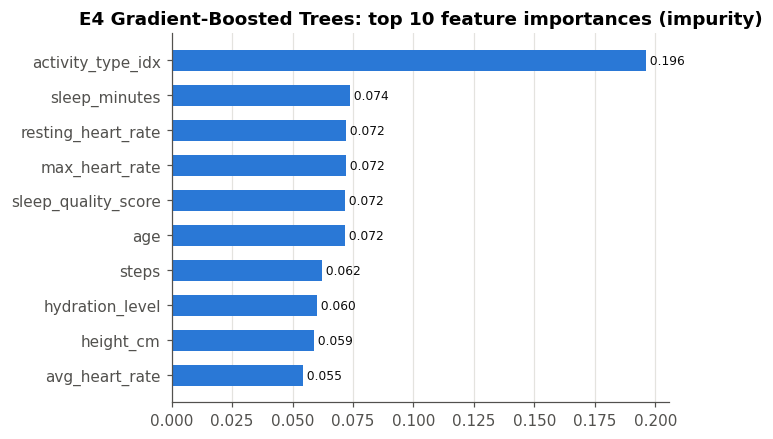


Interpretation (computed from the tables above)
  Gradient-Boosted Trees     Accuracy 0.5036 = majority baseline 0.5079 -0.4 points
  Logistic Regression        Accuracy 0.5040 = majority baseline 0.5079 -0.4 points
  Random Forest              Accuracy 0.5056 = majority baseline 0.5079 -0.2 points
  ROC-AUC of the valid models: 0.496-0.500 (0.5 = chance); with a label-encoding column the accuracy becomes 0.788-0.974: INVALID.


In [10]:
r4, i4 = results("E4"), info("E4")
SPLIT4 = "test (user-held-out)"
print(f"median active_minutes of the training users = {i4['median_active_minutes']}; rows {i4['rows']}; users {i4['users']}; High share {i4['high_share']}")
print("users present in BOTH train and test (must be 0):", i4["users_in_train_and_test"])
cols4 = [ACC, F1M, AUC, BASE]
t4 = wide(r4, SPLIT4, cols4)
print("\nE4 comparison table - TEST users never seen in training:"); display(t4.round(4))
model_bars(t4, ACC, t4[BASE].iloc[0], "E4 user-held-out accuracy")
model_bars(t4, AUC, 0.5, "E4 user-held-out ROC-AUC", baseline_label="chance level")
print("VALIDATION users:"); display(wide(r4, "validation (user-held-out)", cols4).round(4))

cm = pd.read_csv(SUP / "E4_confusion_matrices.csv").set_index("model")
fig, axes = plt.subplots(1, len(cm), figsize=(3.1 * len(cm), 2.9))
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("blues", ["#ffffff", BLUE])
for ax, (name, row) in zip(np.atleast_1d(axes), cm.iterrows()):
    mat = np.array([[row["TN (Low->Low)"], row["FP (Low->High)"]], [row["FN (High->Low)"], row["TP (High->High)"]]])
    ax.imshow(mat, cmap=cmap, vmin=0, vmax=mat.max())
    for (y, x), v in np.ndenumerate(mat):
        ax.text(x, y, f"{int(v):,}", ha="center", va="center", fontsize=9, color="white" if v > 0.6 * mat.max() else INK)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["pred Low", "pred High"], fontsize=8); ax.set_yticks([0, 1]); ax.set_yticklabels(["actual Low", "actual High"], fontsize=8)
    ax.set_title(name, fontsize=9); ax.grid(False)
plt.tight_layout(); plt.show()
display(cm)

print("LEAKAGE tests - calories_burned or sedentary_minutes added (INVALID, they encode the label):")
display(invalid_rows(r4, [ACC, F1M, AUC]).round(4).assign(status="INVALID"))
validity_chart(r4, SPLIT4, AUC, "E4 ROC-AUC: valid models vs leakage runs")
importance_chart("E4", "Random Forest"); importance_chart("E4", "Gradient-Boosted Trees")

print("\nInterpretation (computed from the tables above)")
gains(t4, ACC, t4[BASE].iloc[0], "majority baseline")
lk4 = invalid_rows(r4, [ACC, AUC])
print(f"  ROC-AUC of the valid models: {t4[AUC].min():.3f}-{t4[AUC].max():.3f} (0.5 = chance); with a label-encoding column the accuracy becomes {lk4[ACC].min():.3f}-{lk4[ACC].max():.3f}: INVALID.")

**Reading E4.** Once the columns that encode the label are removed, the remaining physiological and profile features **do not predict whether a day is a high- or low-activity day** for unseen users:
accuracy is at the baseline and ROC-AUC is near 0.5. The leakage runs are almost perfect only because `sedentary_minutes` and `calories_burned` are *derived from* `active_minutes` in this dataset (section 5), so they are **INVALID**.
This is the honest consequence of the derived-data note: the 'excellent' score was always a formula, not learning.

### 7.2 E5 - same-day calorie regression (Linear Regression kept; Random Forest and GBT regressors added)

**E5 is kept:** the Linear Regression, its features (steps, distance, active minutes, average and resting heart rate, age, height, **weight_kg**, BMI, gender), its seeded hash split of (user, date) 70/15/15 and its validation-chosen `regParam`
(`models/train_calorie_regression.py`, imported not edited). Added on exactly the same rows and features: a **Random Forest Regressor** and a **GBT Regressor** (depth, iterations tuned on validation RMSE).
Baselines: always predicting the **training mean** (MAE about 334.5 kcal), and a one-feature Linear Regression on `active_minutes`. A chronological check (train before 2024-10-15) is repeated for all models.
`weight_kg` is kept here: it is the true body-weight term of the calorie formula, and the target is the same-day value, so a calendar clock cannot leak the label.
**Derived-data note:** `calories_burned = MET x weight_kg x duration/60` with `duration == active_minutes`, so the target is a *formula of columns that are in the data*; linear models cannot represent the product, tree models can approximate it.

rows {'train': 70085, 'validation': 15052, 'test': 14985}; same split as the existing E5 run: True; settings {'linreg': {'reg': 0.0}, 'rf': {'depth': 10}, 'gbt': {'depth': 5, 'iters': 100}}
the existing Linear Regression is reproduced: max |difference| to its saved test metrics = 0.0e+00; training mean = 662.46 kcal

E5 comparison table - TEST set (random hash split):


metric,MAE (kcal),RMSE (kcal),R2
model,,,
Baseline: Linear Regression on active_minutes only,247.4010,337.9889,0.3912
Baseline: training mean,334.5102,433.1706,-0.0000
GBT Regressor,183.2806,250.4144,0.6658
Linear Regression,199.7126,263.6442,0.6296
Random Forest Regressor,188.6141,258.6774,0.6434


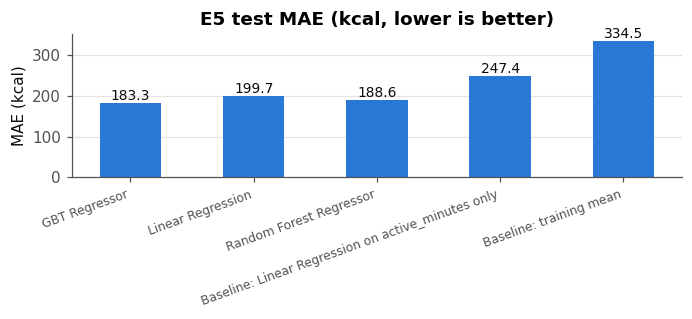

Chronological check (train before the cutoff, test on/after it):


metric,MAE (kcal),RMSE (kcal),R2
model,,,
Baseline: training mean,395.2072,548.2178,-0.1630
GBT Regressor,235.8624,317.9913,0.6087
Linear Regression,247.1993,329.2855,0.5804
Random Forest Regressor,238.8484,325.1463,0.5909


LEAKAGE test - calories_roll7_avg (Silver window includes the day itself) added (INVALID):


metric,MAE (kcal),RMSE (kcal),R2,status
model,,,,
GBT Regressor + calories_roll7_avg incl. the day itself (LEAKAGE),157.7677,218.7608,0.7450,INVALID
Linear Regression + calories_roll7_avg incl. the day itself (LEAKAGE),177.3695,236.0019,0.7032,INVALID
Random Forest Regressor + calories_roll7_avg incl. the day itself (LEAKAGE),163.7059,227.6724,0.7237,INVALID


REFERENCE - activity_type and intensity added (they fix the MET value: formula recovery, not a skill claim):


metric,MAE (kcal),RMSE (kcal),R2
model,,,
GBT Regressor + activity_type & intensity (formula recovery),21.7033,31.0995,0.9948
Linear Regression + activity_type & intensity (formula recovery),110.0234,154.9854,0.8720
Random Forest Regressor + activity_type & intensity (formula recovery),49.4389,72.3022,0.9721


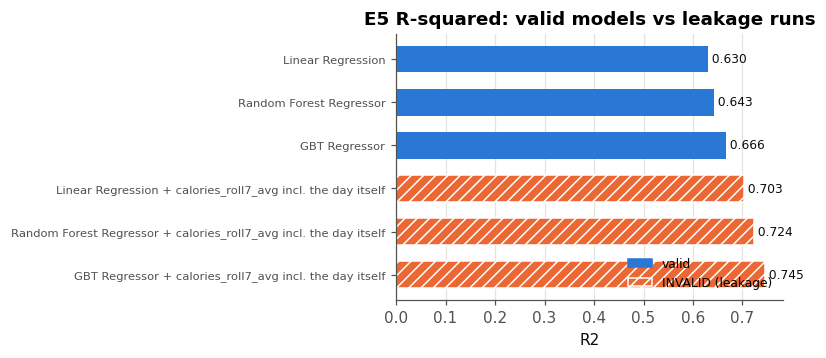

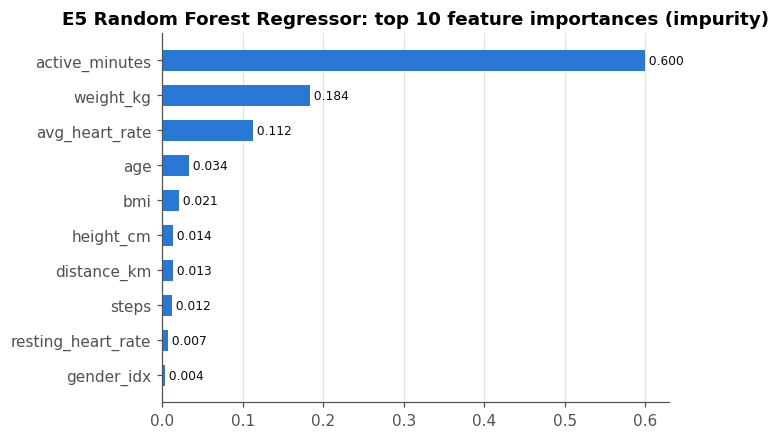

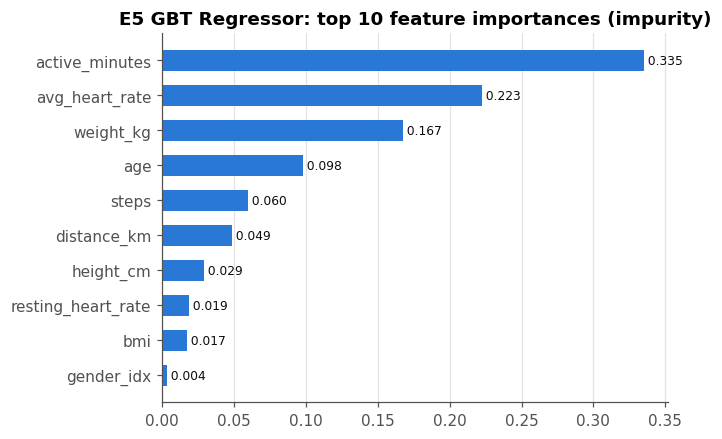


Interpretation (computed from the tables above)
  GBT Regressor              MAE 183.3 kcal = 45.2% lower than the training-mean baseline (334.5 kcal); R2 0.666
  Linear Regression          MAE 199.7 kcal = 40.3% lower than the training-mean baseline (334.5 kcal); R2 0.630
  Random Forest Regressor    MAE 188.6 kcal = 43.6% lower than the training-mean baseline (334.5 kcal); R2 0.643


In [11]:
r5, i5 = results("E5"), info("E5")
print(f"rows {i5['rows']}; same split as the existing E5 run: {i5['same_split_as_existing_E5']}; settings {i5['settings']}")
print(f"the existing Linear Regression is reproduced: max |difference| to its saved test metrics = {i5['reproduction_max_abs_diff']:.1e}; training mean = {i5['train_mean_kcal']:.2f} kcal")
cols5 = [MAE, RMSE, R2]
t5 = wide(r5, "test", cols5, status=("VALID", "BASELINE"))
print("\nE5 comparison table - TEST set (random hash split):"); display(t5.round(4))
v5 = t5.drop(index=[i for i in t5.index if i.startswith("Baseline")])
model_bars(t5.loc[list(v5.index) + [i for i in t5.index if i.startswith("Baseline")]], MAE, None, "E5 test MAE (kcal, lower is better)", fmt="{:.1f}")
print("Chronological check (train before the cutoff, test on/after it):")
chrono = [s for s in r5.split_type.unique() if s.startswith("chronological")][0]
display(wide(r5, chrono, cols5, status=("VALID", "BASELINE")).round(4))
print("LEAKAGE test - calories_roll7_avg (Silver window includes the day itself) added (INVALID):")
display(invalid_rows(r5, cols5).round(4).assign(status="INVALID"))
print("REFERENCE - activity_type and intensity added (they fix the MET value: formula recovery, not a skill claim):")
display(wide(r5, "test", cols5, status=("REFERENCE",)).round(4))
validity_chart(r5, "test", R2, "E5 R-squared: valid models vs leakage runs")
importance_chart("E5", "Random Forest Regressor"); importance_chart("E5", "GBT Regressor")

print("\nInterpretation (computed from the tables above)")
bm = float(t5.loc["Baseline: training mean", MAE])
for m in v5.index:
    print(f"  {m:26s} MAE {v5.loc[m, MAE]:.1f} kcal = {100 * (1 - v5.loc[m, MAE] / bm):.1f}% lower than the training-mean baseline ({bm:.1f} kcal); R2 {v5.loc[m, R2]:.3f}")

**Reading E5.** All three models beat the mean-prediction baseline by a wide margin. The tree regressors can approximate the product MET x weight x minutes, which the linear model cannot, so they score better;
that is *formula recovery inside a dataset where calories are computed from other columns*, not evidence that calories can be measured from steps. Adding activity type and intensity (which fix the MET value) is shown only as a reference.
The leakage run adds a rolling mean that includes the day's own calories and is **INVALID**.

### 7.3 Verification of every experiment

1. **Leakage test:** each experiment was run once with a forbidden / label-encoding feature; those rows are stored with status `INVALID` and are never cited as results.
2. **Baseline comparison:** every score is printed next to the majority-class (or training-mean) baseline.
3. **Unseen-data evaluation:** E1 also user-held-out, E2 chronological, E3 stratified cross-validation, E4 user-held-out, E5 also chronological.
4. **Independent scikit-learn cross-check** (`scripts/sup_sklearn_crosscheck.py`, no Spark): metrics recomputed from the saved predictions, labels and window features rebuilt in pandas, and independent refits.
5. **HDFS rerun:** the same scripts run against the Silver data read from HDFS (section 11.6).

In [12]:
HEADLINE = {"E1": ("test", AUC), "E2": ("chronological test", AUC), "E3": ("stratified 5-fold CV (out-of-fold)", AUC),
            "E4": ("test (user-held-out)", AUC), "E5": ("test", R2)}
rows = []
for exp, (split, metric) in HEADLINE.items():
    res = results(exp)
    bad = res[(res.status == "INVALID") & (res.metric == metric)]
    for _, r in bad.iterrows():
        base_model = r.model.split(" + ")[0]
        ok = res[(res.model == base_model) & (res.split_type == split) & (res.metric == metric) & (res.status == "VALID")]
        rows.append({"experiment": exp, "leaky run (INVALID)": r.model.replace(" (LEAKAGE)", ""), "metric": metric,
                     "leaky score": r.value, "same model without the leak": float(ok.value.iloc[0]) if len(ok) else np.nan})
leak = pd.DataFrame(rows).assign(status="INVALID")
leak["inflation"] = leak["leaky score"] - leak["same model without the leak"]
print("Leakage tests: score with a forbidden feature vs the same model without it"); display(leak.round(4))
print("every leakage row has status INVALID:", bool((pd.concat([results(e) for e in HEADLINE]).query("model.str.contains('LEAKAGE')", engine='python').status == "INVALID").all()))

cc = pd.read_csv(SUP / "hdfs_rerun" / "sklearn_crosscheck.csv")
local_vs_hdfs_max = pd.read_csv(SUP / "local_vs_hdfs_comparison.csv")["abs_diff"].max()
print(f"\nCross-check run on the HDFS-rerun outputs ({len(cc)} checks); local results match the HDFS rerun within {local_vs_hdfs_max:.2e} (see local_vs_hdfs_summary.md).")
print(f"Independent scikit-learn cross-check: {int(cc['pass'].sum())}/{len(cc)} checks passed")
display(cc.groupby(["experiment", "kind"])["pass"].agg(checks="count", passed="sum"))
print("largest differences (metric recomputation, tolerance 1e-9 or 2e-3 for ROC-AUC; refits have wider, stated tolerances):")
display(cc.sort_values("abs_diff", ascending=False).head(6)[["experiment", "check", "spark_value", "sklearn_value", "abs_diff", "tolerance", "pass"]].round(6))
assert cc["pass"].all(), "a cross-check failed - see sklearn_crosscheck.csv"


Leakage tests: score with a forbidden feature vs the same model without it


,experiment,leaky run (INVALID),metric,leaky score,same model without the leak,status,inflation
0,E1,Random Forest + steps & distance_km,ROC AUC,0.9996,0.7585,INVALID,0.2411
1,E1,Logistic Regression + steps & distance_km,ROC AUC,1.0000,0.7396,INVALID,0.2604
2,E1,Gradient-Boosted Trees + steps & distance_km,ROC AUC,0.9996,0.7735,INVALID,0.2261
3,E2,Random Forest + rolling mean INCLUDING the pre...,ROC AUC,0.7518,0.6706,INVALID,0.0811
4,E2,Gradient-Boosted Trees + rolling mean INCLUDIN...,ROC AUC,0.8257,0.6970,INVALID,0.1287
5,E2,Logistic Regression + rolling mean INCLUDING t...,ROC AUC,0.8787,0.7004,INVALID,0.1783
6,E3,Random Forest + average steps,ROC AUC,0.7978,0.5425,INVALID,0.2553
7,E3,Logistic Regression + average steps,ROC AUC,0.8242,0.5486,INVALID,0.2756
8,E4,Random Forest + calories_burned,ROC AUC,0.8905,0.4965,INVALID,0.3941
9,E4,Gradient-Boosted Trees + calories_burned,ROC AUC,0.9673,0.4999,INVALID,0.4674


every leakage row has status INVALID: True

Cross-check run on the HDFS-rerun outputs (103 checks); local results match the HDFS rerun within 6.76e-05 (see local_vs_hdfs_summary.md).
Independent scikit-learn cross-check: 103/103 checks passed


checks  passed
experiment kind                           
E1         recompute            24      24
           refit                 2       2
           refit (approx.)       1       1
E2         features              3       3
           no-future-info        1       1
           recompute            18      18
           refit                 2       2
           refit (approx.)       1       1
E3         label                 1       1
           leakage rule          1       1
           recompute             8       8
           refit (approx.)       4       4
E4         label                 1       1
           leakage               1       1
           recompute            18      18
           refit                 2       2
           split                 1       1
           status                1       1
E5         recompute            10      10
           refit                 2       2
           refit (approx.)       1       1

largest differences (metric recomputation, tolerance 1e-9 or 2e-3 for ROC-AUC; refits have wider, stated tolerances):


,experiment,check,spark_value,sklearn_value,abs_diff,tolerance,pass
51,E2,Random Forest: independent sklearn refit (appr...,0.670612,0.647138,0.023474,0.05,True
63,E3,Logistic Regression: independent sklearn CV (s...,0.548553,0.569289,0.020736,0.05,True
64,E3,Random Forest: independent sklearn CV (same fo...,0.535469,0.549199,0.013730,0.05,True
65,E3,Random Forest: independent sklearn CV (same fo...,0.542478,0.533095,0.009384,0.05,True
62,E3,Logistic Regression: independent sklearn CV (s...,0.537757,0.542334,0.004577,0.05,True
102,E5,Random Forest Regressor: independent sklearn r...,0.643385,0.645902,0.002517,0.05,True


## 8. Big Data / Spark Evidence

### 8.1 Spark Session

In [47]:
sc = spark.sparkContext
jvm = spark._jvm
hadoop_conf = sc._jsc.hadoopConfiguration()
spark_info = {
    "Spark version": spark.version,
    "Application name": sc.appName,
    "Application id": sc.applicationId,
    "Master": sc.master,
    "Default parallelism (cores used)": sc.defaultParallelism,
    "spark.sql.shuffle.partitions": spark.conf.get("spark.sql.shuffle.partitions"),
    "Spark UI": sc.uiWebUrl,
    "JVM Java version": jvm.System.getProperty("java.version"),
    "Hadoop client library version": jvm.org.apache.hadoop.util.VersionInfo.getVersion(),
    "fs.defaultFS (default filesystem)": hadoop_conf.get("fs.defaultFS"),
}
display(pd.DataFrame(spark_info.items(), columns=["Property", "Value"]))

,Property,Value
0,Spark version,4.0.1
1,Application name,FitPulse-Faculty-Demo
2,Application id,local-1791224961473
3,Master,local[*]
4,Default parallelism (cores used),12
5,spark.sql.shuffle.partitions,8
6,Spark UI,http://127.0.0.1:4040
7,JVM Java version,17.0.20.1
8,Hadoop client library version,3.4.1
9,fs.defaultFS (default filesystem),file:///


### 8.2 Distributed Data Processing

The physical plans show how Spark parallelises the ETL's operations. The window functions use an
`Exchange hashpartitioning(user_id)` (shuffle) followed by `Window`. The per-user goal aggregation runs as
a partial `HashAggregate` on each partition (map side), an `Exchange` (shuffle), then a final
`HashAggregate` (reduce side), which is the MapReduce pattern. The join with the per-user table is a
`BroadcastHashJoin`.

In [48]:
def plan_of(df):
    buf = io.StringIO()
    with contextlib.redirect_stdout(buf):
        df.explain()
    return buf.getvalue()

etl_like = (bronze.withColumn("steps_lag1", F.lag("steps", 1).over(Window.partitionBy("user_id").orderBy("date"))))
goals = bronze.groupBy("user_id").agg(F.avg("steps").alias("user_avg_steps"))
joined = bronze.join(F.broadcast(goals), "user_id")
plans = {"Window / lag feature (spark_etl.py L79-82)": plan_of(etl_like),
         "groupBy(user_id).agg - personalized goal (spark_etl.py L99-104)": plan_of(goals),
         "Broadcast join (spark_etl.py L115)": plan_of(joined)}
for title, p in plans.items():
    print("=" * 100, "\n", title, "\n", "=" * 100, "\n", p, sep="")

Window / lag feature (spark_etl.py L79-82)
== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Window [lag(steps#58, -1, null) windowspecdefinition(user_id#56, date#57 ASC NULLS FIRST, specifiedwindowframe(RowFrame, -1, -1)) AS steps_lag1#133368], [user_id#56], [date#57 ASC NULLS FIRST]
   +- Sort [user_id#56 ASC NULLS FIRST, date#57 ASC NULLS FIRST], false, 0
      +- Exchange hashpartitioning(user_id#56, 8), ENSURE_REQUIREMENTS, [plan_id=11508]
         +- FileScan csv [user_id#56,date#57,steps#58,calories_burned#59,distance_km#60,active_minutes#61,sedentary_minutes#62,resting_heart_rate#63,avg_heart_rate#64,max_heart_rate#65,sleep_minutes#66,sleep_quality_score#67,activity_type#68,intensity#69,age#70,gender#71,height_cm#72,weight_kg#73,bmi#74,health_condition#75,smoking_status#76,stress_level#77,hydration_level#78] Batched: false, DataFilters: [], Format: CSV, Location: InMemoryFileIndex(1 paths)[file:/D:/bigdata/fitpulsee/FitPulse/data/raw/fitpulse_raw.csv], PartitionFilters

In [13]:
# Spark MLlib stages of the supervised experiments (pipelines are built, not fitted, here)
import sys
sys.path.insert(0, str(PROJECT_ROOT / "models"))
import sup_common as S
from pyspark.ml.classification import GBTClassifier, LogisticRegression, RandomForestClassifier
from pyspark.ml.regression import GBTRegressor, LinearRegression, RandomForestRegressor
examples = {
    "E1-E4 Random Forest classifier": S.make_pipeline(["x"], ["c"], RandomForestClassifier()),
    "E1-E4 Gradient-Boosted Trees classifier": S.make_pipeline(["x"], ["c"], GBTClassifier()),
    "E1-E4 Logistic Regression (one-hot + scaled)": S.make_pipeline(["x"], ["c"], LogisticRegression(), onehot=True, scale=True),
    "E5 Linear Regression (one-hot + scaled)": S.make_pipeline(["x"], ["c"], LinearRegression(), onehot=True, scale=True),
    "E5 Random Forest / GBT regressors": S.make_pipeline(["x"], ["c"], RandomForestRegressor()),
}
mllib_stages = pd.DataFrame([(name, type(s).__name__) for name, p in examples.items() for s in p.getStages()],
                            columns=["Supervised model pipeline", "Spark MLlib stage"])
print("Spark MLlib components used by the supervised experiments:")
display(mllib_stages)

Spark MLlib components used by the supervised experiments:


,Supervised model pipeline,Spark MLlib stage
0,E1-E4 Random Forest classifier,StringIndexer
1,E1-E4 Random Forest classifier,VectorAssembler
2,E1-E4 Random Forest classifier,RandomForestClassifier
3,E1-E4 Gradient-Boosted Trees classifier,StringIndexer
4,E1-E4 Gradient-Boosted Trees classifier,VectorAssembler
5,E1-E4 Gradient-Boosted Trees classifier,GBTClassifier
6,E1-E4 Logistic Regression (one-hot + scaled),StringIndexer
7,E1-E4 Logistic Regression (one-hot + scaled),OneHotEncoder
8,E1-E4 Logistic Regression (one-hot + scaled),VectorAssembler
9,E1-E4 Logistic Regression (one-hot + scaled),StandardScaler


### 8.3 Partitions

In [50]:
silver_files = sorted(Path(SILVER_PATH).rglob("*.parquet"))
by_month = pd.Series([f.parent.name for f in silver_files]).value_counts().sort_index()
storage = pd.DataFrame({"Parquet files": by_month,
                        "Size (KB)": [round(sum(f.stat().st_size for f in silver_files if f.parent.name == m) / 1024, 1)
                                      for m in by_month.index]})
print(f"Silver layer on disk: {len(silver_files)} Parquet files in {len(by_month)} month partitions, "
      f"{sum(f.stat().st_size for f in silver_files) / 1024 / 1024:.2f} MB total")
display(storage)

print("Bronze DataFrame in-memory partitions :", bronze.rdd.getNumPartitions())
print("Silver DataFrame in-memory partitions :", silver.rdd.getNumPartitions())
print("Records per in-memory Silver partition:")
(silver.groupBy(F.spark_partition_id().alias("partition_id")).count().orderBy("partition_id").show(50))

Silver layer on disk: 96 Parquet files in 12 month partitions, 6.97 MB total


,Parquet files,Size (KB)
month=2024-01,8,626.5
month=2024-02,8,635.7
month=2024-03,8,691.3
month=2024-04,8,677.3
month=2024-05,8,670.1
month=2024-06,8,617.8
month=2024-07,8,588.1
month=2024-08,8,549.0
month=2024-09,8,515.5
month=2024-10,8,530.2


Bronze DataFrame in-memory partitions : 3
Silver DataFrame in-memory partitions : 12
Records per in-memory Silver partition:


+------------+-----+
|partition_id|count|
+------------+-----+
|           0|10708|
|           1|10170|
|           2| 9671|
|           3| 9431|
|           4| 8838|
|           5| 8539|
|           6| 7948|
|           7| 7618|
|           8| 7272|
|           9| 7064|
|          10| 7526|
|          11| 5337|
+------------+-----+



In [51]:
march = silver.filter(F.col("month") == "2024-03")
march_plan = plan_of(march)
print("Partition pruning - query for month = 2024-03 only reads that folder:")
scan = [line for line in march_plan.splitlines() if "FileScan parquet" in line][0]
print("PartitionFilters:", re.search(r"PartitionFilters: \[(.*?)\]", scan).group(1))
print("Location        :", re.search(r"Location: InMemoryFileIndex\(\d+ paths\)\[(.*?)\]", scan).group(1))
print("\nRows in 2024-03 partition:", march.count())

Partition pruning - query for month = 2024-03 only reads that folder:
PartitionFilters: isnotnull(month#117), (month#117 = 2024-03)
Location        : file:/D:/bigdata/fitpulsee/FitPulse/data/processed/fitpulse_silver



Rows in 2024-03 partition: 10246


### 8.4 HDFS Evidence (baseline recorded BEFORE the HDFS upgrade)

The check below looks for a Hadoop/HDFS installation and the configured default filesystem, and does not
assume either. **Its saved output is the local-only baseline** from the session in which sections 1-10 were
executed (no HDFS on that PATH). The HDFS integration and its verification are in **section 11**.

In [52]:
hdfs_bin = shutil.which("hdfs")
print("`hdfs` command on PATH :", hdfs_bin)
print("fs.defaultFS           :", hadoop_conf.get("fs.defaultFS"))
if hdfs_bin:
    out = subprocess.run([hdfs_bin, "dfs", "-ls", "/"], capture_output=True, text=True)
    print(out.stdout or out.stderr)
else:
    print("\nRESULT: HDFS is NOT installed/configured on this machine. The Silver layer is stored as\n"
          "partitioned Parquet on the local filesystem through Hadoop's FileSystem API (file:///),\n"
          "i.e. the same storage format/partition layout HDFS would hold, but not HDFS itself.")

evidence_txt = ["SPARK SESSION"] + [f"{k}: {v}" for k, v in spark_info.items()]
evidence_txt += ["", f"hdfs command on PATH: {hdfs_bin}", "",
                 f"Silver: {len(silver_files)} parquet files, {len(by_month)} month partitions",
                 storage.to_string(), "", "Bronze partitions: " + str(bronze.rdd.getNumPartitions()),
                 "Silver partitions: " + str(silver.rdd.getNumPartitions()), ""]
evidence_txt += [f"--- {t} ---\n{p}" for t, p in plans.items()] + ["--- Partition pruning ---", march_plan]
(EVIDENCE / "spark_hdfs_evidence.txt").write_text("\n".join(evidence_txt), encoding="utf-8")
print("Saved faculty_evidence/spark_hdfs_evidence.txt")

`hdfs` command on PATH : None
fs.defaultFS           : file:///

RESULT: HDFS is NOT installed/configured on this machine. The Silver layer is stored as
partitioned Parquet on the local filesystem through Hadoop's FileSystem API (file:///),
i.e. the same storage format/partition layout HDFS would hold, but not HDFS itself.
Saved faculty_evidence/spark_hdfs_evidence.txt


**What can honestly be claimed:**
* ✅ Processing is done with **Apache Spark** (DataFrames, window functions, shuffles, broadcast joins,
  Spark SQL in `etl/spark_benchmarks.py`) and **Spark MLlib** (pipelines, Random Forest, Gradient-Boosted Trees, Logistic / Linear Regression, evaluators).
* ✅ Storage uses the Big Data columnar format (**Parquet**) with **Hive-style partitioning** and partition pruning.
* ⚠️ Spark runs in **local mode** (`local[*]`), using all CPU cores of one machine as parallel executors.
  The code is cluster-ready: only `.master()` and the storage URI (`hdfs://…`) would change.
* ✅ **Update:** this paragraph describes the state when §8.4 was recorded. HDFS has since been installed and verified (§11): claim only what §11 prints, and describe it as a single-node deployment.

## 9. Final Results

The consolidated table below is generated from `exports/E1_results.csv` ... `E5_results.csv` (the same files Power BI can import: `experiment_id, model, metric, value, split_type, status`).
Only `VALID` and `BASELINE` rows appear; `INVALID` leakage runs and `REFERENCE` contrast runs are excluded on purpose.

In [14]:
HEAD = {"E1": ("test", [ACC, F1W, AUC, BASE]), "E2": ("chronological test", [ACC, P1, R1, F11, AUC, BASE]),
        "E3": ("stratified 5-fold CV (out-of-fold)", [ACC, F1W, AUC, BASE]), "E4": ("test (user-held-out)", [ACC, F1M, AUC, BASE])}
frames = []
for exp, (split, cols) in HEAD.items():
    t = wide(results(exp), split, cols).reset_index().assign(experiment=exp, evaluation=split)
    frames.append(t)
final_cls = pd.concat(frames, ignore_index=True)
final_cls = final_cls[["experiment", "model", "evaluation"] + [c for c in final_cls.columns if c not in ("experiment", "model", "evaluation")]]
print("Classification experiments (headline evaluation of each):"); display(final_cls.round(4))
final_reg = wide(results("E5"), "test", [MAE, RMSE, R2], status=("VALID", "BASELINE")).reset_index().assign(experiment="E5", evaluation="test (random hash split)")
print("Regression experiment E5:"); display(final_reg.round(4))
SUP.mkdir(exist_ok=True)
final_cls.to_csv(SUP / "final_metric_table_classification.csv", index=False); final_reg.to_csv(SUP / "final_metric_table_regression.csv", index=False)
print("saved faculty_evidence/supervised/final_metric_table_classification.csv and final_metric_table_regression.csv")

Classification experiments (headline evaluation of each):


metric,experiment,model,evaluation,Accuracy,F1 (weighted),ROC AUC,Baseline accuracy (always majority class),Precision (positive class),Recall (positive class),F1 (positive class),F1 (macro)
0,E1,Gradient-Boosted Trees,test,0.7382,0.7381,0.7735,0.6144,NaN,NaN,NaN,NaN
1,E1,Logistic Regression,test,0.7356,0.7305,0.7396,0.6144,NaN,NaN,NaN,NaN
2,E1,Random Forest,test,0.7352,0.7346,0.7585,0.6144,NaN,NaN,NaN,NaN
3,E2,Gradient-Boosted Trees,chronological test,0.5991,NaN,0.6970,0.5886,0.5080,0.8039,0.6226,NaN
4,E2,Logistic Regression,chronological test,0.6835,NaN,0.7004,0.5886,0.6649,0.4654,0.5475,NaN
5,E2,Random Forest,chronological test,0.5823,NaN,0.6706,0.5886,0.4954,0.8179,0.6170,NaN
6,E3,Logistic Regression,stratified 5-fold CV (out-of-fold),0.5378,0.5361,0.5486,0.5011,NaN,NaN,NaN,NaN
7,E3,Random Forest,stratified 5-fold CV (out-of-fold),0.5355,0.5318,0.5425,0.5011,NaN,NaN,NaN,NaN
8,E4,Gradient-Boosted Trees,test (user-held-out),0.5036,NaN,0.4999,0.5079,NaN,NaN,NaN,0.5002
9,E4,Logistic Regression,test (user-held-out),0.5040,NaN,0.4999,0.5079,NaN,NaN,NaN,0.4442


Regression experiment E5:


metric,model,MAE (kcal),RMSE (kcal),R2,experiment,evaluation
0,Baseline: Linear Regression on active_minutes ...,247.4010,337.9889,0.3912,E5,test (random hash split)
1,Baseline: training mean,334.5102,433.1706,-0.0000,E5,test (random hash split)
2,GBT Regressor,183.2806,250.4144,0.6658,E5,test (random hash split)
3,Linear Regression,199.7126,263.6442,0.6296,E5,test (random hash split)
4,Random Forest Regressor,188.6141,258.6774,0.6434,E5,test (random hash split)


saved faculty_evidence/supervised/final_metric_table_classification.csv and final_metric_table_regression.csv


## 10. Final Inference

In [15]:
t1_ = wide(results("E1"), "test", [ACC, AUC, BASE]); t2_ = wide(results("E2"), "chronological test", [ACC, AUC, BASE])
t3_ = wide(results("E3"), "stratified 5-fold CV (out-of-fold)", [ACC, AUC, BASE]); t4_ = wide(results("E4"), "test (user-held-out)", [ACC, AUC, BASE])
t5_ = wide(results("E5"), "test", [MAE, R2], status=("VALID", "BASELINE"))
v5_ = t5_[~t5_.index.str.startswith("Baseline")]
rng = lambda s: f"{s.min():.3f}-{s.max():.3f}"
print(f'''1. DATA: {len(silver_pd):,} daily records from {silver_pd.user_id.nunique()} users, processed by Apache Spark (Bronze CSV -> Silver partitioned Parquet).
   Several columns (calories, distance, active/sedentary minutes, max heart rate, sleep quality) are partly derived in this demonstration dataset.

2. E1 same-day goal: accuracy {rng(t1_[ACC])} and ROC-AUC {rng(t1_[AUC])} for Random Forest, Logistic Regression and GBT, against a {t1_[BASE].iloc[0]:.3f} majority baseline.
3. E2 next-day goal (history only, chronological test): accuracy {rng(t2_[ACC])}, ROC-AUC {rng(t2_[AUC])}, against an always-'missed' baseline of {t2_[BASE].iloc[0]:.3f}.
   The signal is weak and the goal rate drifts over the year; a random split would have looked much better and would have been misleading.
4. E3 user-level high_achiever (437 users, 5-fold CV): accuracy {rng(t3_[ACC])}, ROC-AUC {rng(t3_[AUC])}, baseline {t3_[BASE].iloc[0]:.3f}: no reliable skill from profile averages.
5. E4 activity level (unseen users): accuracy {rng(t4_[ACC])}, ROC-AUC {rng(t4_[AUC])}, baseline {t4_[BASE].iloc[0]:.3f}: near chance once the label-encoding columns are removed.
6. E5 calories: MAE {v5_[MAE].min():.1f}-{v5_[MAE].max():.1f} kcal and R2 {rng(v5_[R2])} against MAE {t5_.loc['Baseline: training mean', MAE]:.1f} kcal for always predicting the training mean.

7. EVERY leakage run is marked INVALID, and the scikit-learn cross-check passed {int(cc['pass'].sum())}/{len(cc)} checks.''')

1. DATA: 100,122 daily records from 437 users, processed by Apache Spark (Bronze CSV -> Silver partitioned Parquet).
   Several columns (calories, distance, active/sedentary minutes, max heart rate, sleep quality) are partly derived in this demonstration dataset.

2. E1 same-day goal: accuracy 0.735-0.738 and ROC-AUC 0.740-0.773 for Random Forest, Logistic Regression and GBT, against a 0.614 majority baseline.
3. E2 next-day goal (history only, chronological test): accuracy 0.582-0.684, ROC-AUC 0.671-0.700, against an always-'missed' baseline of 0.589.
   The signal is weak and the goal rate drifts over the year; a random split would have looked much better and would have been misleading.
4. E3 user-level high_achiever (437 users, 5-fold CV): accuracy 0.535-0.538, ROC-AUC 0.542-0.549, baseline 0.501: no reliable skill from profile averages.
5. E4 activity level (unseen users): accuracy 0.504-0.506, ROC-AUC 0.496-0.500, baseline 0.508: near chance once the label-encoding columns are rem

**Limitations (stated honestly):**
* The data is a public Kaggle dataset. `calories_burned`, `distance_km`, `active_minutes`, `sedentary_minutes`, `max_heart_rate` and `sleep_quality_score` are **partly derived** (section 5); scores on them can be formula recovery.
* In this synthetic data `weight_kg` drifts almost linearly with the calendar inside each user and the goal rate is seasonal. E1 and E5 keep `weight_kg` as specified; E2 and E3 use a baseline weight instead; E1's top feature may therefore be a calendar clock (no ablation was run).
* E2's chronological blocks differ strongly in goal rate (train / validation / test), so accuracy must be read against the test-block baseline and ROC-AUC is the fairer summary.
* E3 has only 437 users, so its accuracy has a standard error of about 2.4 percentage points; E3 and E4 are best read as 'no reliable skill', not as small positive results.
* Spark runs in local mode. HDFS is a single-node deployment (replication 1, section 11); the local run and the HDFS rerun are compared in 11.6.
* The legacy Streamlit dashboard still contains an unsupervised Isolation Forest (heart-rate anomaly flagging, `models/train_anomaly_detection.py`). It is not one of E1-E5 and was not changed.
* Power BI and the web page were built from the earlier experiments and have not been rewired to the supervised `exports/E<n>_results.csv` files.

## 11. HDFS Storage and Spark Integration

Sections 1-10 above were produced from **local Parquet** (`file:///`), because HDFS was not installed at the time
(§8.4 records that state). This section documents the HDFS upgrade and **every cell below runs against the live
cluster**; if HDFS is not reachable the cells say `NOT VERIFIED` and nothing is faked.

| | Local Parquet (fallback) | HDFS (this section) |
|---|---|---|
| Where | `data/processed/fitpulse_silver/` on the Windows disk | `hdfs://localhost:9000/fitpulse/silver` in the DataNode's block storage |
| Run with | `python etl/spark_etl.py` | `python etl/spark_etl.py --storage hdfs --hdfs-uri hdfs://localhost:9000` (or `.\run_fitpulse_hdfs.ps1`) |
| Served by | Windows file system | NameNode (metadata) + DataNode (blocks), Hadoop 3.4.1, single node, replication 1 |
| If the store is down | n/a | the ETL **exits with code 2** - it never falls back to local disk |

Architecture actually implemented: `Raw CSV -> prepare_raw_dataset.py -> HDFS /fitpulse/bronze -> Spark ETL (cleaning + features) -> HDFS /fitpulse/silver (Parquet, month=) -> Spark MLlib -> (SQLite export) -> Streamlit`.
Only the Bronze/Silver storage moved to HDFS; the Gold table, SQLite export and the scikit-learn models used by Streamlit still use local files.

In [56]:
# 11.1 Verified HDFS URI and active storage mode  (real CLI calls against the running NameNode)
import os, re, subprocess
HADOOP_DIR = TOOLS / "hadoop-3.4.1"
HDFS_ENV = {**os.environ, "HADOOP_HOME": str(HADOOP_DIR), "HADOOP_CONF_DIR": str(PROJECT_ROOT / "hadoop-conf"),
            "JAVA_HOME": str(TOOLS / "jdk17"), "HADOOP_LOG_DIR": str(TOOLS / "hdfs-logs")}

def hdfs(*args, timeout=90):
    p = subprocess.run([str(HADOOP_DIR / "bin" / "hdfs.cmd"), *args], capture_output=True, text=True,
                       env=HDFS_ENV, timeout=timeout)
    return p.returncode, (p.stdout + p.stderr).strip()

rc, uri = hdfs("getconf", "-confKey", "fs.defaultFS")
rc2, ls_root = hdfs("dfs", "-ls", "/")
HDFS_OK = rc == 0 and rc2 == 0 and uri.startswith("hdfs://")
HDFS_URI = uri.splitlines()[-1].strip() if HDFS_OK else None
HDFS_SILVER = f"{HDFS_URI}/fitpulse/silver" if HDFS_OK else None
LOCAL_SILVER_URI = "file:///" + str((PROJECT_ROOT / "data/processed/fitpulse_silver").resolve()).replace("\\", "/")

print("hdfs getconf -confKey fs.defaultFS ->", uri if HDFS_OK else f"FAILED ({uri[:200]})")
print("\n$ hdfs dfs -ls /\n" + ls_root)
if HDFS_OK:
    print(f"\nSTORAGE MODE : HDFS ({HDFS_URI})   <-- verified: both commands succeeded")
    print("Silver (HDFS):", HDFS_SILVER)
    print("Silver (local fallback, unchanged):", LOCAL_SILVER_URI)
else:
    print("\nSTORAGE MODE : NOT VERIFIED - HDFS is not reachable. Start it with .\\start_hdfs.ps1 and re-run this section.")

hdfs getconf -confKey fs.defaultFS -> hdfs://localhost:9000

$ hdfs dfs -ls /
Found 1 items
drwxr-xr-x   - Abhirami S supergroup          0 2026-10-11 13:36 /fitpulse

STORAGE MODE : HDFS (hdfs://localhost:9000)   <-- verified: both commands succeeded
Silver (HDFS): hdfs://localhost:9000/fitpulse/silver
Silver (local fallback, unchanged): file:///D:/bigdata/fitpulsee/FitPulse/data/processed/fitpulse_silver


In [57]:
# 11.2 HDFS directory listing and space usage
if HDFS_OK:
    rc, out = hdfs("dfs", "-ls", "-R", "/fitpulse")
    lines = out.splitlines()
    print("$ hdfs dfs -ls -R /fitpulse   (first 12 of %d entries)" % len(lines))
    print("\n".join(lines[:12]))
    print("\n$ hdfs dfs -du -h /fitpulse")
    print(hdfs("dfs", "-du", "-h", "/fitpulse")[1])
    print("\n$ hdfs dfsadmin -report   (summary)")
    rep = hdfs("dfsadmin", "-report")[1].splitlines()
    print("\n".join(l for l in rep if l.startswith(("Configured Capacity", "DFS Used:", "Live datanodes", "Name:", "Hostname"))))
else:
    print("NOT VERIFIED - HDFS not reachable")

$ hdfs dfs -ls -R /fitpulse   (first 12 of 113 entries)
drwxr-xr-x   - Abhirami S supergroup          0 2026-10-11 13:24 /fitpulse/_selftest_1791705267
drwxr-xr-x   - Abhirami S supergroup          0 2026-10-11 13:35 /fitpulse/bronze
-rw-r--r--   1 Abhirami S supergroup   11745183 2026-10-11 13:35 /fitpulse/bronze/fitpulse_raw.csv
drwxr-xr-x   - Abhirami S supergroup          0 2026-10-11 13:36 /fitpulse/silver
-rw-r--r--   1 Abhirami S supergroup          0 2026-10-11 13:36 /fitpulse/silver/_SUCCESS
drwxr-xr-x   - Abhirami S supergroup          0 2026-10-11 13:36 /fitpulse/silver/month=2024-01
-rw-r--r--   1 Abhirami S supergroup      71726 2026-10-11 13:36 /fitpulse/silver/month=2024-01/part-00000-0e7d3e93-3851-4dc3-98ee-e544d3192fa2.c000.snappy.parquet
-rw-r--r--   1 Abhirami S supergroup      83271 2026-10-11 13:36 /fitpulse/silver/month=2024-01/part-00001-0e7d3e93-3851-4dc3-98ee-e544d3192fa2.c000.snappy.parquet
-rw-r--r--   1 Abhirami S supergroup      84715 2026-10-11 13:36 /fitp

0       0       /fitpulse/_selftest_1791705267
11.2 M  11.2 M  /fitpulse/bronze
7.0 M   7.0 M   /fitpulse/silver

$ hdfs dfsadmin -report   (summary)


Configured Capacity: 240871534592 (224.33 GB)
DFS Used: 19206268 (18.32 MB)
Live datanodes (1):
Name: 127.0.0.1:9866 (127.0.0.1)
Hostname: localhost
Configured Capacity: 240871534592 (224.33 GB)
DFS Used: 19206268 (18.32 MB)


In [58]:
# 11.3 Actual Spark read FROM HDFS: schema, record count, partition layout
if HDFS_OK:
    hsilver = spark.read.parquet(HDFS_SILVER)
    print("Spark read:", HDFS_SILVER)
    print("File system class behind the path:",
          spark._jvm.org.apache.hadoop.fs.Path(HDFS_SILVER).getFileSystem(spark._jsc.hadoopConfiguration()).getClass().getName())
    print(f"Record count : {hsilver.count():,}")
    print(f"Columns      : {len(hsilver.columns)}")
    hsilver.printSchema()
    # Parquet partition layout straight from the HDFS listing
    rows = []
    for l in hdfs("dfs", "-ls", "-R", "/fitpulse/silver")[1].splitlines():
        m = re.search(r"(\d+)\s+\d{4}-\d\d-\d\d \d\d:\d\d\s+(\S+\.parquet)$", l)      # owner names may contain spaces
        if m:
            rows.append({"partition": m.group(2).split("/")[3], "bytes": int(m.group(1))})
    layout = (pd.DataFrame(rows).groupby("partition").agg(parquet_files=("bytes", "size"), size_KB=("bytes", lambda s: round(s.sum()/1024, 1))))
    layout.loc["TOTAL"] = [layout.parquet_files.sum(), round(layout.size_KB.sum(), 1)]
    display(layout)
    print("Example HDFS path:", "/fitpulse/silver/month=2024-03/part-0000x-....snappy.parquet")
else:
    print("NOT VERIFIED - HDFS not reachable")

Spark read: hdfs://localhost:9000/fitpulse/silver
File system class behind the path: org.apache.hadoop.hdfs.DistributedFileSystem


Record count : 100,122
Columns      : 39
root
 |-- user_id: integer (nullable = true)
 |-- date: date (nullable = true)
 |-- steps: integer (nullable = true)
 |-- calories_burned: double (nullable = true)
 |-- distance_km: double (nullable = true)
 |-- active_minutes: integer (nullable = true)
 |-- sedentary_minutes: integer (nullable = true)
 |-- resting_heart_rate: double (nullable = true)
 |-- avg_heart_rate: integer (nullable = true)
 |-- max_heart_rate: integer (nullable = true)
 |-- sleep_minutes: integer (nullable = true)
 |-- sleep_quality_score: double (nullable = true)
 |-- activity_type: string (nullable = true)
 |-- intensity: string (nullable = true)
 |-- age: integer (nullable = true)
 |-- gender: string (nullable = true)
 |-- height_cm: double (nullable = true)
 |-- weight_kg: double (nullable = true)
 |-- bmi: double (nullable = true)
 |-- health_condition: string (nullable = true)
 |-- smoking_status: string (nullable = true)
 |-- stress_level: integer (nullable = true

,parquet_files,size_KB
partition,,
month=2024-01,8.0,626.5
month=2024-02,8.0,635.7
month=2024-03,8.0,691.3
month=2024-04,8.0,677.3
month=2024-05,8.0,670.1
month=2024-06,8.0,617.8
month=2024-07,8.0,588.1
month=2024-08,8.0,549.0
month=2024-09,8.0,515.5


Example HDFS path: /fitpulse/silver/month=2024-03/part-0000x-....snappy.parquet


In [59]:
# 11.4 Write / read-back verification with a small scratch dataset (own directory, removed afterwards)
import time as _t
if HDFS_OK:
    scratch = f"{HDFS_URI}/fitpulse/_nb_selftest_{int(_t.time())}"
    expected = {(1, "alpha", 10.5), (2, "beta", 20.25), (3, "gamma", 30.0)}
    vals = ", ".join(f"({i}, '{n}', {v}D)" for i, n, v in sorted(expected))
    spark.sql(f"SELECT * FROM VALUES {vals} AS t(id, name, value)").write.mode("errorifexists").parquet(scratch)
    back = spark.read.parquet(scratch)
    got = {(r.id, r.name, r.value) for r in back.collect()}
    print("Wrote then read back:", scratch)
    print("Schema     :", back.schema.simpleString())
    print("Row count  :", back.count(), "(expected 3)")
    print("Values     :", sorted(got))
    print("Values identical:", got == expected)
    print("\n$ hdfs dfs -ls", scratch.replace(HDFS_URI, ""))
    print(hdfs("dfs", "-ls", scratch.replace(HDFS_URI, ""))[1])
    assert got == expected and back.count() == 3
    p = spark._jvm.org.apache.hadoop.fs.Path(scratch)
    p.getFileSystem(spark._jsc.hadoopConfiguration()).delete(p, True)       # only the scratch dir created above
    print("\nScratch directory removed. WRITE/READ-BACK VERIFIED")
else:
    print("NOT VERIFIED - HDFS not reachable")

Wrote then read back: hdfs://localhost:9000/fitpulse/_nb_selftest_1791706059
Schema     : struct<id:int,name:string,value:double>


Row count  : 3 (expected 3)
Values     : [(1, 'alpha', 10.5), (2, 'beta', 20.25), (3, 'gamma', 30.0)]
Values identical: True

$ hdfs dfs -ls /fitpulse/_nb_selftest_1791706059


Found 4 items
-rw-r--r--   3 Abhirami S supergroup          0 2026-10-11 13:37 /fitpulse/_nb_selftest_1791706059/_SUCCESS
-rw-r--r--   3 Abhirami S supergroup        975 2026-10-11 13:37 /fitpulse/_nb_selftest_1791706059/part-00000-f87d4957-8bf2-4e64-94f4-7ea9bd30f059-c000.snappy.parquet
-rw-r--r--   3 Abhirami S supergroup        968 2026-10-11 13:37 /fitpulse/_nb_selftest_1791706059/part-00001-f87d4957-8bf2-4e64-94f4-7ea9bd30f059-c000.snappy.parquet
-rw-r--r--   3 Abhirami S supergroup        975 2026-10-11 13:37 /fitpulse/_nb_selftest_1791706059/part-00002-f87d4957-8bf2-4e64-94f4-7ea9bd30f059-c000.snappy.parquet



Scratch directory removed. WRITE/READ-BACK VERIFIED


In [60]:
# 11.5 HDFS Silver vs local-Parquet Silver (same ETL code, different storage)
if HDFS_OK:
    lsilver = spark.read.parquet(LOCAL_SILVER_URI)
    cols = sorted(lsilver.columns)
    print(f"local rows = {lsilver.count():,} | HDFS rows = {hsilver.count():,} | same columns = {cols == sorted(hsilver.columns)}")
    only_local = lsilver.select(cols).exceptAll(hsilver.select(cols)).count()
    only_hdfs = hsilver.select(cols).exceptAll(lsilver.select(cols)).count()
    print(f"rows only in local = {only_local}, rows only in HDFS = {only_hdfs}  ->",
          "IDENTICAL" if only_local == only_hdfs == 0 else "DIFFERENT")
    rpt = json.loads((EVIDENCE / "hdfs" / "etl_hdfs_run_report.json").read_text())
    print("\nETL run report (faculty_evidence/hdfs/etl_hdfs_run_report.json):")
    print(json.dumps(rpt, indent=2))
else:
    print("NOT VERIFIED - HDFS not reachable")

local rows = 100,122 | HDFS rows = 100,122 | same columns = True


rows only in local = 0, rows only in HDFS = 0  -> IDENTICAL

ETL run report (faculty_evidence/hdfs/etl_hdfs_run_report.json):
{
  "storage_mode": "hdfs",
  "hdfs_uri": "hdfs://localhost:9000",
  "input_path": "hdfs://localhost:9000/fitpulse/bronze/fitpulse_raw.csv",
  "output_path": "hdfs://localhost:9000/fitpulse/silver",
  "bronze_rows": 100122,
  "clean_rows": 100122,
  "silver_rows_written": 100122,
  "silver_rows_read_back": 100122,
  "silver_columns": 39,
  "elapsed_seconds": 13.2
}


In [16]:
# 11.6 The SUPERVISED experiments re-run on the Silver data READ FROM HDFS (run_supervised.ps1 -Storage hdfs; results saved separately)
hd = EVIDENCE / "supervised" / "hdfs_rerun"
if (hd / "exports" / "E1_results.csv").exists():
    rows = []
    for exp in ("E1", "E2", "E3", "E4", "E5"):
        a, b = pd.read_csv(EXPORTS / f"{exp}_results.csv"), pd.read_csv(hd / "exports" / f"{exp}_results.csv")
        j = a.merge(b, on=["experiment_id", "model", "metric", "split_type", "status"], suffixes=("_local", "_hdfs"), how="outer", indicator=True)
        both = j[j._merge == "both"]
        d = (both.value_local - both.value_hdfs).abs()
        rows.append({"experiment": exp, "rows compared": len(both), "only in one run": int((j._merge != "both").sum()),
                     "max |local - HDFS|": d.max(), "rows differing by more than 1e-6": int((d > 1e-6).sum())})
    cmp_ = pd.DataFrame(rows)
    display(cmp_)
    for exp in ("E1", "E2", "E3", "E4", "E5"):
        ri = json.loads((hd / f"{exp}_run_info.json").read_text(encoding="utf-8"))
        print(f"{exp}: storage mode used = {ri['storage_mode'].upper()}  |  Silver source = {ri['silver_source']}")
    cc_h = pd.read_csv(hd / "sklearn_crosscheck.csv") if (hd / "sklearn_crosscheck.csv").exists() else None
    if cc_h is not None:
        print(f"scikit-learn cross-check on the HDFS rerun: {int(cc_h['pass'].sum())}/{len(cc_h)} passed")
else:
    print("NOT VERIFIED - run .\\run_fitpulse_hdfs.ps1 -SkipEtl and then .\\run_supervised.ps1 -Experiment All -Storage hdfs first")

,experiment,rows compared,only in one run,max |local - HDFS|,rows differing by more than 1e-6
0,E1,69,0,6.759577e-05,10
1,E2,75,0,7.944833e-06,1
2,E3,66,0,0.000000e+00,0
3,E4,78,0,0.000000e+00,0
4,E5,60,0,5.684342e-14,0


E1: storage mode used = HDFS  |  Silver source = hdfs://localhost:9000/fitpulse/silver
E2: storage mode used = HDFS  |  Silver source = hdfs://localhost:9000/fitpulse/silver
E3: storage mode used = HDFS  |  Silver source = hdfs://localhost:9000/fitpulse/silver
E4: storage mode used = HDFS  |  Silver source = hdfs://localhost:9000/fitpulse/silver
E5: storage mode used = HDFS  |  Silver source = hdfs://localhost:9000/fitpulse/silver
scikit-learn cross-check on the HDFS rerun: 103/103 passed


In [62]:
# 11.7 Behaviour when HDFS is unavailable (test recorded by scripts/test_hdfs_down.ps1 while the NameNode was stopped)
f = EVIDENCE / "hdfs" / "failure_mode_test.txt"
print(f.read_text(encoding="utf-8") if f.exists() else "NOT VERIFIED - test not run yet")

﻿FAILURE-MODE TEST  2026-10-11T13:34:39
local Silver BEFORE: 194 files, 7369100 bytes, newest write 2026-10-05T23:59:14.0692020+05:30

--- A) HDFS selected, NameNode stopped ---
exit code: 2
  ERROR: HDFS mode selected but the NameNode at localhost:9000 is unreachable ([WinError 10061] No connection could be made because the target machine actively refused it). Start it with .\start_hdfs.ps1. Refusing to fall back to local storage.
local Silver AFTER : 194 files, 7369100 bytes, newest write 2026-10-05T23:59:14.0692020+05:30
local Silver untouched: True

--- B) HDFS selected but no URI configured ---
exit code: 2
  ERROR: HDFS mode selected but no HDFS URI given. Pass --hdfs-uri or set FITPULSE_HDFS_URI (run_fitpulse_hdfs.ps1 reads it from `hdfs getconf -confKey fs.defaultFS`).

--- C) LOCAL mode (explicit fallback) while HDFS is down; output to a scratch dir ---
exit code: 0
  STORAGE MODE : LOCAL filesystem (Parquet fallback - NOT HDFS)
  Silver rows written   : 100,122
  Read back fr

**Reading this section.** The architecture claim is supported only by the cells above that print `VERIFIED` /
identical-row results. Anything printed as `NOT VERIFIED` means the check could not be run. Local Parquet remains
available as an explicit fallback (`python etl/spark_etl.py`, no flags); HDFS mode is opt-in and never degrades silently.
Limitations: single-node cluster (replication 1, so no fault tolerance), Spark still runs in `local[*]`, the
scikit-learn models and Streamlit dashboard read the local SQLite/joblib artefacts, not HDFS.

**About the HDFS rerun in 11.6:** it re-executes E1-E5 with the Silver dataset read from HDFS (`run_supervised.ps1 -Storage hdfs`; it never falls back to local files) and compares every result row with the local run. Differences larger than floating-point noise would be listed in the table; ROC-AUC can differ in the last digits because Spark's reading order, and therefore its floating-point accumulation order, may differ (probable cause, not proven by a separate experiment). Also note: the scratch files written by this notebook's Spark session carry replication 3 (the kernel does not load `hadoop-conf`), whereas the ETL writes replication 1; the scratch directory was deleted.

## 12. Dashboards (Power BI is the primary dashboard) and faculty-proof checklist

**Power BI** - `powerbi/FitPulse_PowerBI_Dashboard.pbix`, saved by Power BI Desktop 2.158 from a generated Power BI Project (`powerbi/build_powerbi.py`).
Five pages: Fitness Overview, Activity and Sleep, Calorie Prediction, User Segmentation, Model Evaluation (70 visuals, 34 DAX measures). It imports validated **CSV exports** of the Silver data and the saved
model results; it does **not** read HDFS (single node, replication factor 1). The five experiments (E1-E5) are shown one at a time and never combined.
Verified in Desktop: the `.pbix` reopens with data cached; card values equal independent pandas values; the Activity type slicer (Cycling) changes the cards to the expected values.
Not verified: the other slicers individually, cross-page behaviour. Full record: `faculty_evidence/powerbi/POWERBI_VALIDATION.md`.

**Streamlit** (`dashboard/app.py`) is the earlier per-user dashboard, kept as a **legacy/optional** component. It was tested with Streamlit's AppTest (below); that testing found and fixed a Windows crash
(`strftime('%-d')`). Its data source is the local SQLite database, not HDFS.

**Status after the supervised conversion:** the Power BI file and the web page were built from the earlier experiments and still show the previous E3/E4 K-Means views, which read output files that were deliberately left in place (`faculty_evidence/report_aligned/kmeans_*`, `models/artifacts/kmeans_user_segments_model.json`; the scripts that made them are in `archive/kmeans/`). They have not been rewired to the supervised `exports/E<n>_results.csv` files, which already use the Power BI long format (experiment id, model, metric, value, split type, status).

Power BI file: powerbi\FitPulse_PowerBI_Dashboard.pbix | exists: True | size: 4,508,752 bytes
project_validation: 70/70 automated checks passed
dashboard/dashboard_validation: 15/15 automated checks passed

# PBIX structure check
File: `D:\bigdata\fitpulsee\FitPulse\powerbi\FitPulse_PowerBI_Dashboard.pbix`

| Check | Result | Detail |
|---|---|---|
| PBIX package opens as a zip | PASS | 87 entries, 4,403 KB |
| contains a data model | PASS | ['DataModel'] |
| contains a report definition (Layout or PBIR) | PASS | PBIR |
| page count | PASS | ['Fitness Overview', 'Activity and Sleep', 'Calorie Prediction', 'User Segmentation', 'Model Evaluation'] |
| page exists: Fitness Overview | PASS |  |
| page exists: Activity and Sleep | PASS |  |
| page exists: Calorie Prediction | PASS |  |
| page exists: User Segmentation | PASS |  |
| page exists: Model Evaluation | PASS |  |
| visuals found | PASS | 70 visuals |
| slicers present | PASS | 15 slicers |
| no visual references a nonexistent colu

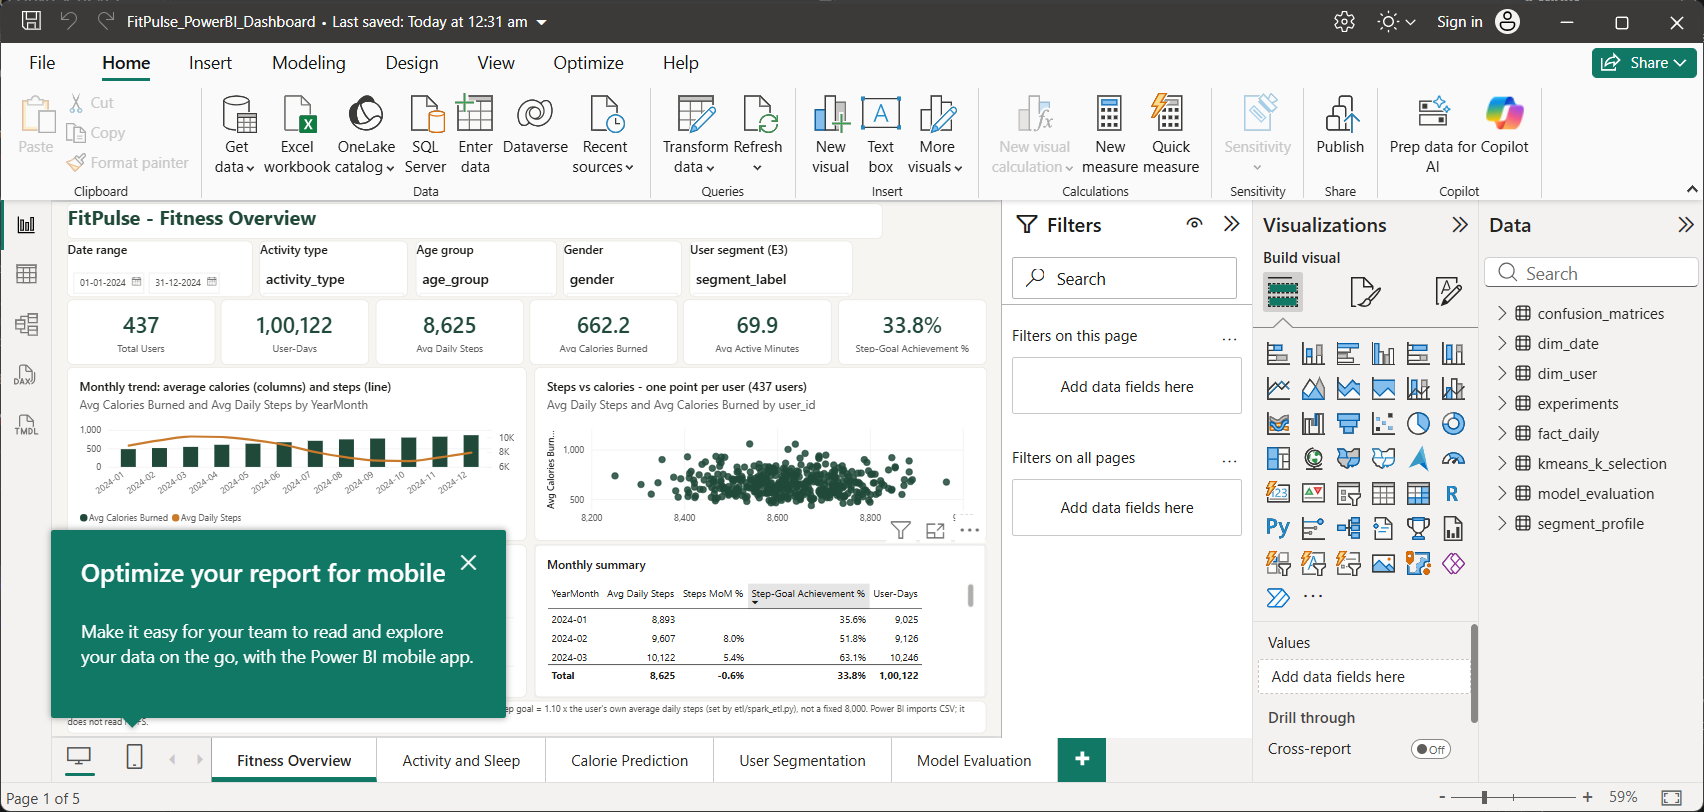

1b_slicer_Cycling_selected.png


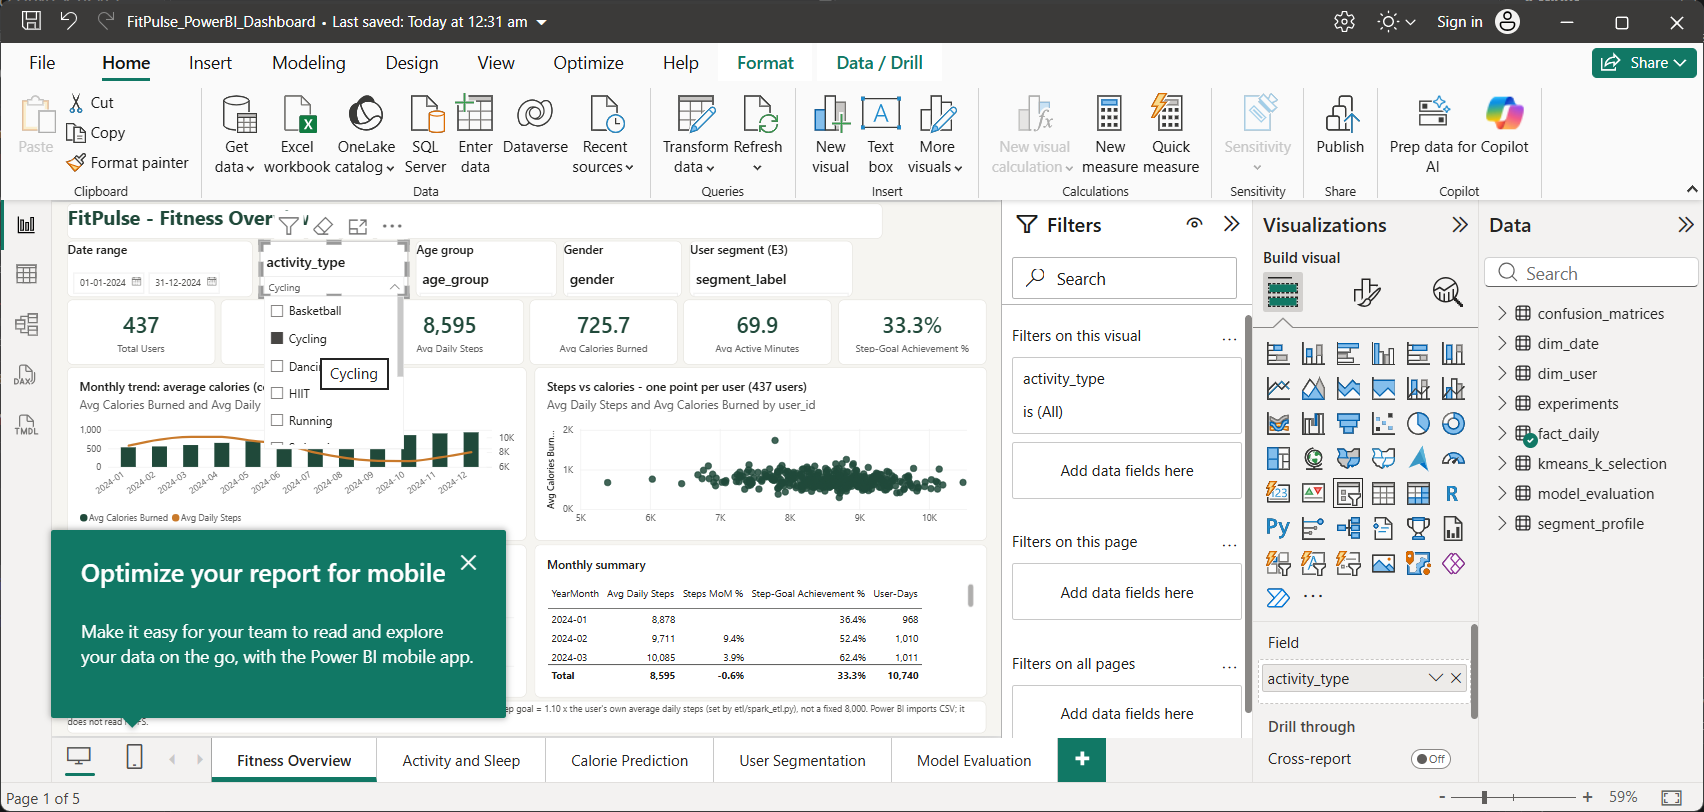

2_Activity_and_Sleep.png


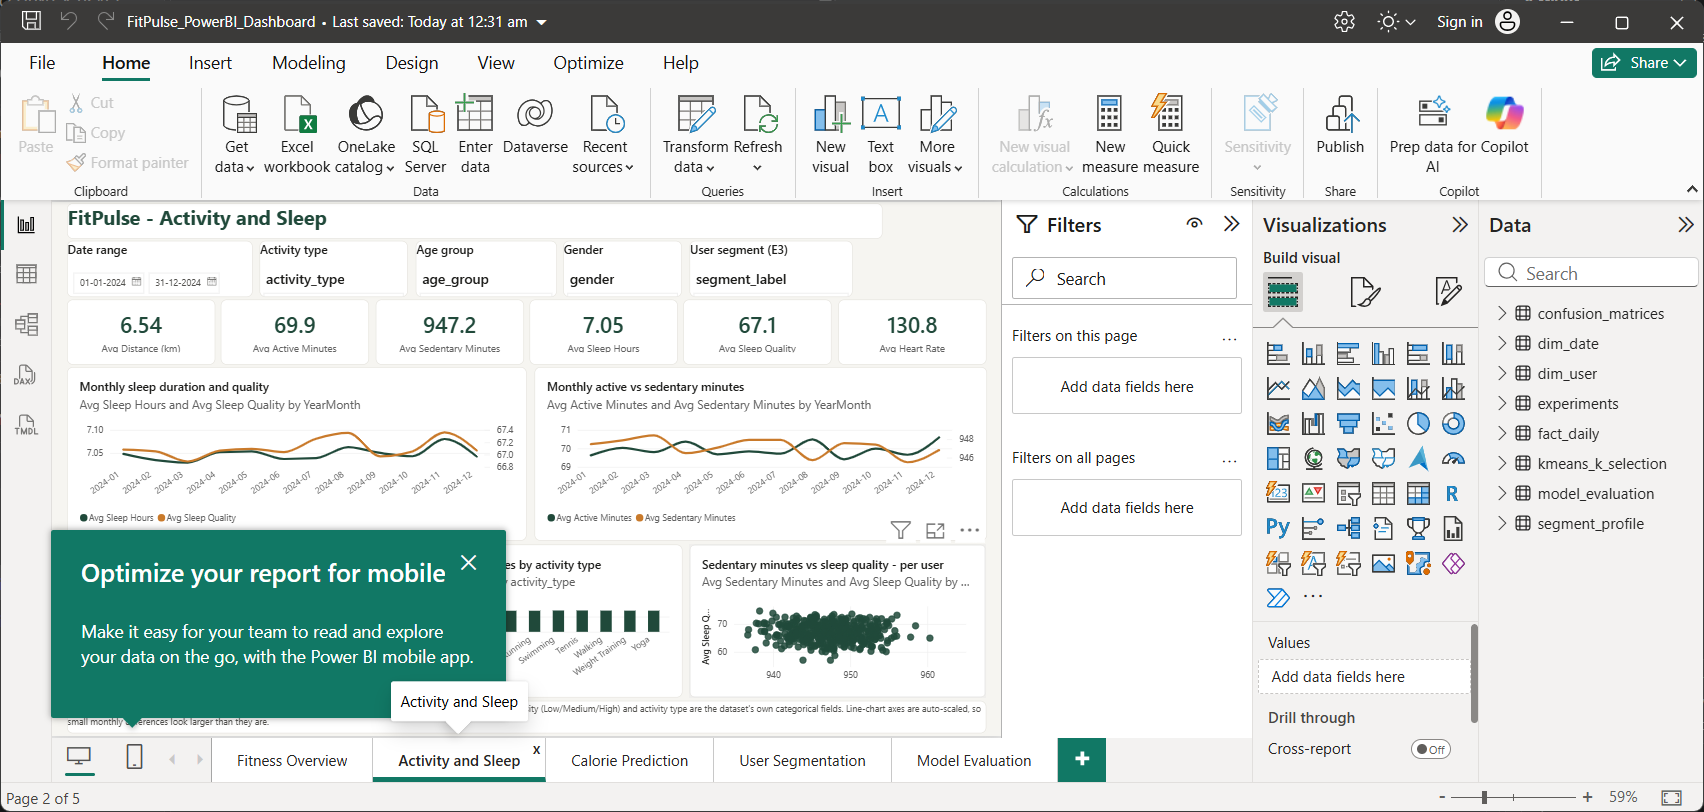

3_Calorie_Prediction.png


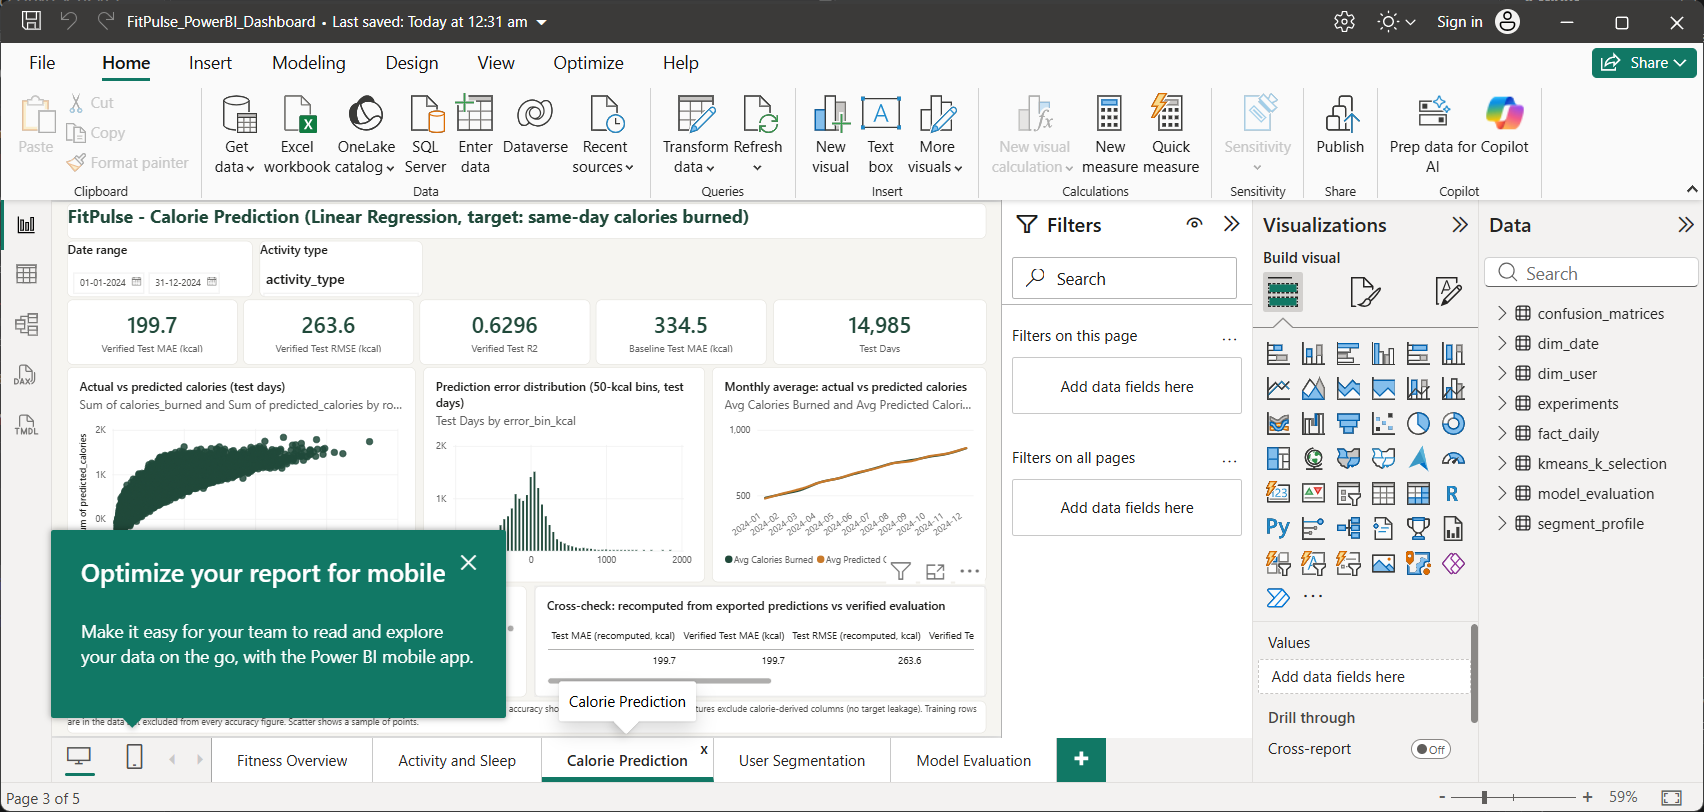

4_User_Segmentation.png


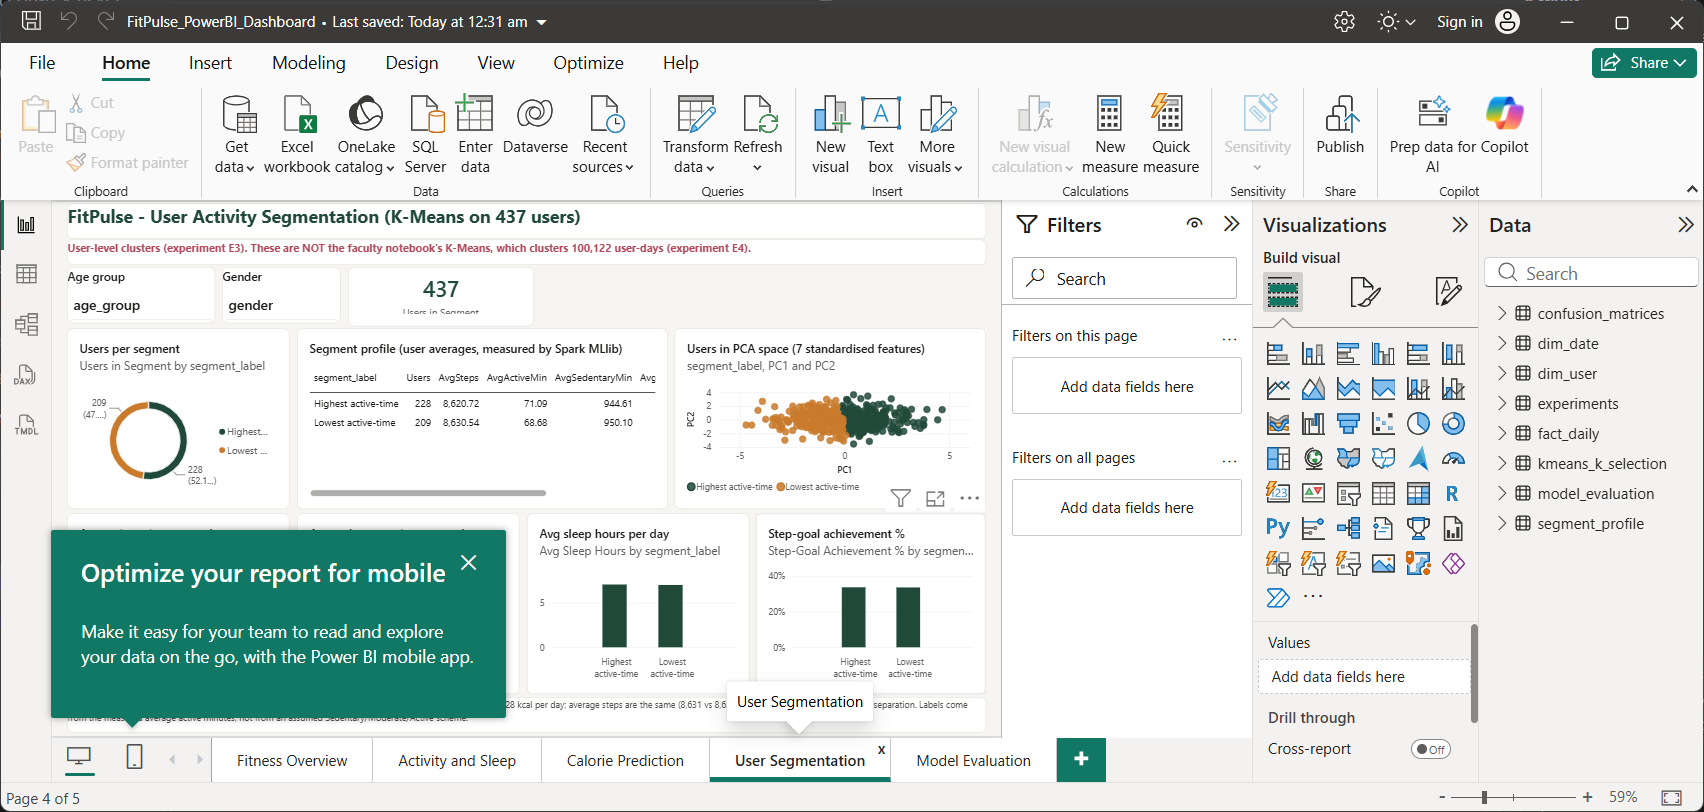

5_Model_Evaluation.png


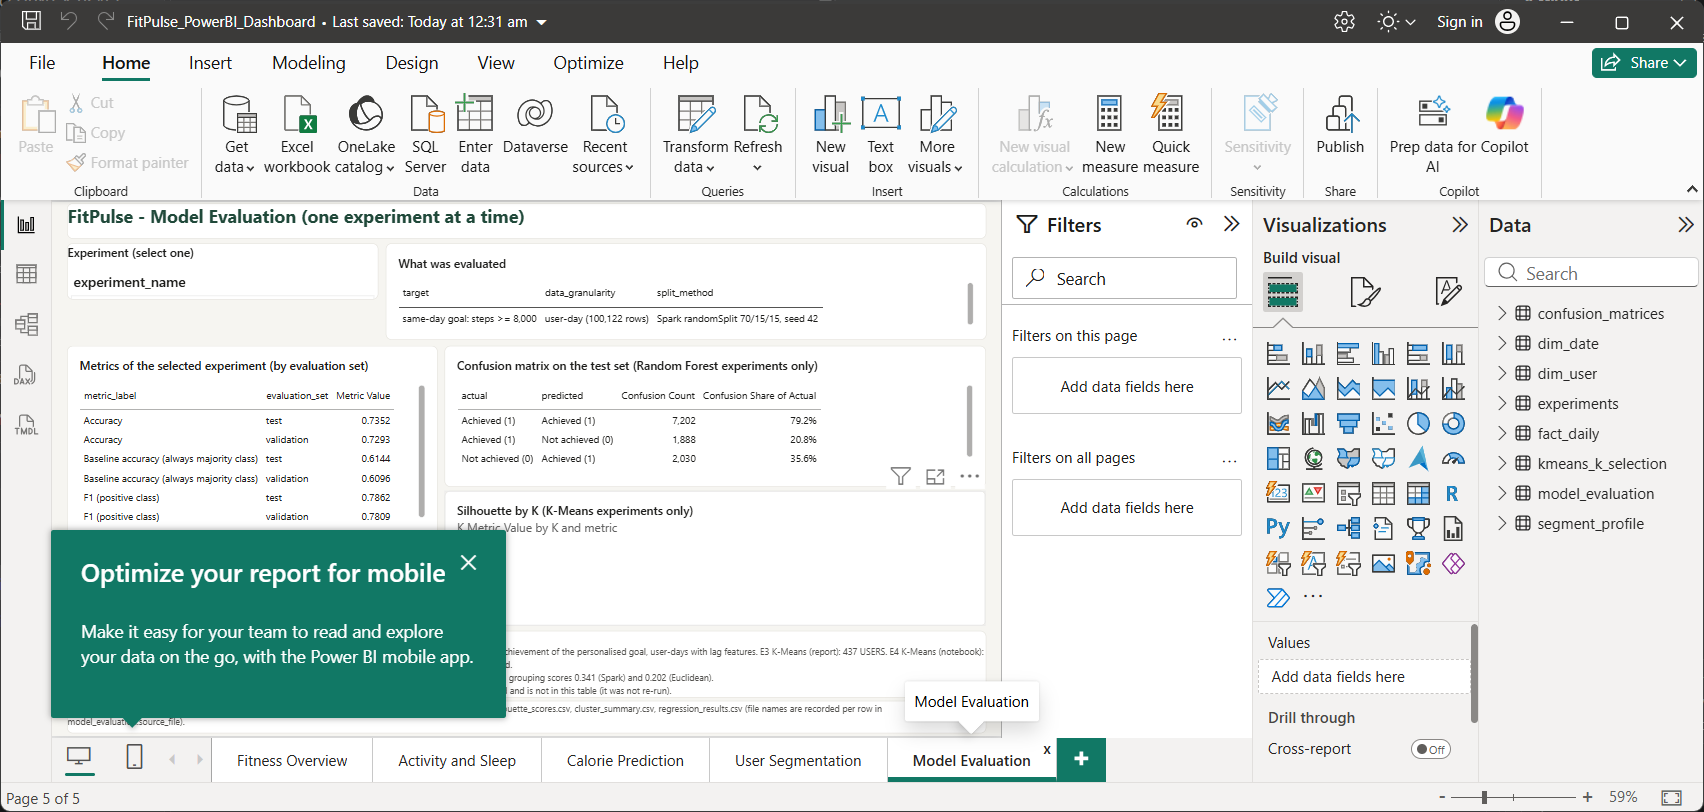

In [67]:
import json
from IPython.display import Image, display
pbix = PROJECT_ROOT / "powerbi" / "FitPulse_PowerBI_Dashboard.pbix"
print("Power BI file:", pbix.relative_to(PROJECT_ROOT), "| exists:", pbix.exists(), "| size: %s bytes" % (f"{pbix.stat().st_size:,}" if pbix.exists() else "n/a"))
for name in ("project_validation", "dashboard/dashboard_validation"):
    f = EVIDENCE / ("powerbi/" + name + ".json" if name == "project_validation" else name + ".json")
    d = json.loads(f.read_text(encoding="utf-8"))
    print(f"{name}: {d['passed']}/{d['total']} automated checks passed")
print()
print((EVIDENCE / "powerbi" / "pbix_structure_check.md").read_text(encoding="utf-8")[:1500])
shots = sorted((EVIDENCE / "powerbi" / "pbix_screenshots").glob("*.png"))
print("Real screenshots of the opened .pbix in Power BI Desktop:", [s.name for s in shots])
for s in shots:
    print(s.name)
    display(Image(filename=str(s), width=900))

In [17]:
mm = pd.read_csv(EVIDENCE / "model_metrics.csv")
print("faculty_evidence/model_metrics.csv holds the PREVIOUS (pre-supervised) experiments; rows:", len(mm))
display(mm[mm.metric.isin(["Accuracy", "ROC AUC", "ROC-AUC", "F1 (goal-achieved class)", "MAE (kcal)", "RMSE (kcal)", "R2"])]
        .drop(columns=["source_file"]).round(4).reset_index(drop=True))
print("\nThe SUPERVISED results are exports/E1_results.csv ... E5_results.csv (sections 5-7). Known limits: Power BI and the web page have not been rewired to them; "
      "the legacy Streamlit app's classifier is Logistic Regression (ROC-AUC 0.755 from models/metrics_report.md, an earlier training run that was not repeated); HDFS is single node; Power BI imports CSV and does not read HDFS.")

faculty_evidence/model_metrics.csv holds the PREVIOUS (pre-supervised) experiments; rows: 69


,model,experiment,set,metric,value
0,Random Forest (Spark MLlib),notebook: next-day personalised goal [local Pa...,test,Accuracy,0.7187
1,Random Forest (Spark MLlib),notebook: next-day personalised goal [local Pa...,test,ROC-AUC,0.8247
2,Random Forest (Spark MLlib),notebook: next-day personalised goal [HDFS re-...,test,Accuracy,0.7187
3,Random Forest (Spark MLlib),notebook: next-day personalised goal [HDFS re-...,test,ROC-AUC,0.8247
4,Random Forest (Spark MLlib),REPORT-aligned: same-day steps >= 8000,validation,Accuracy,0.7293
5,Random Forest (Spark MLlib),REPORT-aligned: same-day steps >= 8000,test,Accuracy,0.7352
6,Random Forest (Spark MLlib),REPORT-aligned: same-day steps >= 8000,validation,F1 (goal-achieved class),0.7809
7,Random Forest (Spark MLlib),REPORT-aligned: same-day steps >= 8000,test,F1 (goal-achieved class),0.7862
8,Random Forest (Spark MLlib),REPORT-aligned: same-day steps >= 8000,validation,ROC AUC,0.7549
9,Random Forest (Spark MLlib),REPORT-aligned: same-day steps >= 8000,test,ROC AUC,0.7585



The SUPERVISED results are exports/E1_results.csv ... E5_results.csv (sections 5-7). Known limits: Power BI and the web page have not been rewired to them; the legacy Streamlit app's classifier is Logistic Regression (ROC-AUC 0.755 from models/metrics_report.md, an earlier training run that was not repeated); HDFS is single node; Power BI imports CSV and does not read HDFS.


In [55]:
spark.stop()
print("Spark session stopped. Evidence files:")
for f in sorted(EVIDENCE.iterdir()):
    print("  ", f.name)

Spark session stopped. Evidence files:
   build_notebook.py
   classification_results.csv
   classification_split_comparison.csv
   cluster_profile_heatmap.png
   cluster_sizes.png
   cluster_summary.csv
   confusion_matrix.csv
   confusion_matrix.png
   dataset_summary.csv
   duplicate_analysis.csv
   final_feature_set.csv
   log_prepare_raw_dataset.txt
   log_spark_etl.txt
   missing_values_bronze.csv
   missing_values_silver.csv
   missing_values_source.csv
   preprocessing_summary.csv
   REPORT_VALUES.md
   rf_feature_importance.csv
   rf_feature_importance.png
   rf_test_predictions.csv
   rf_validation_tuning.csv
   schemas.txt
   silhouette_scores.csv
   silhouette_scores.png
   spark_hdfs_evidence.txt
   split_summary.csv
   statistical_summary.csv
   user_cluster_mix.csv
